<a href="https://colab.research.google.com/github/mamatha050107-blip/Robust-AI-for-pneumonia-detection/blob/main/PneumoniaScansCNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Download the dataset here!**


<a href='https://www.kaggle.com/paultimothymooney/chest-xray-pneumonia' > Link to the dataset from Kaggle.com </a>

# **Quick introduction into the problem**

<h1 align=center><strong>Pneumonia</strong></h1>


---

<p align='center'><a  href='https://nbviewer.jupyter.org/github/M-Borsuk/CNN-Pneumonia-Classification/blob/49cab8e3f2ed89b31c6e9782ccea639b7983320e/PneumoniaScansCNN.ipynb' > View the notebook here for better readability </a></p>

<br>
<br>
<br>
<figure align=center>
  <img src='https://www.nhlbi.nih.gov/sites/default/files/inline-images/pneumonia.png' style='width:100%'>
  <figcaption align='center'> <a href='https://www.nhlbi.nih.gov/health-topics/pneumonia' >Picture 1. Overview of the bacterial pneumonia. [1] </a> </figcaption>
 </figure>
<br>
<br>


---


<p align='center'> As we can read from <a href='https://en.wikipedia.org/wiki/Pneumonia'> Wikipedia</a> , <strong> pneumonia </strong> is a an inflammatory condition of the lung primarily affecting the small air sacs known as alveoli. [Picture 1.]</p>
<br>
<p align='center'>
<strong>Symptoms</strong> can start from mild to serious and may include <strong>coughing with mucus</strong>, <strong>fever</strong>, <strong>chills</strong>, and <strong>heavy breathing</strong>. How serious your pneumonia is depends on your <strong>age</strong> and your overall <strong>health</strong>. <a href='https://www.nhlbi.nih.gov/health-topics/pneumonia' > [2] </a>
</p>
<br>
<p align='center'>
  To diagnose <strong>pneumonia</strong>, your doctor will review your medical history, perform a physical exam, and order diagnostic tests such as a <strong>chest X-ray</strong> [Picture 2,3].</p>
<p align='center'>
This information can help your doctor determine what type of pneumonia you have and what type of treatment to introduce. <a href='https://www.nhlbi.nih.gov/health-topics/pneumonia' > [2] </a>
</p>


---


<br>
<figure align=center>
  <img src='https://i0.wp.com/cdn-prod.medicalnewstoday.com/content/images/articles/322/322091/aspiration-pneumonia-image-credit-melvil-2017-november-13.jpg?w=1155&h=1570' style='width:100%'>
  <figcaption align='center'> <a href='https://www.medicalnewstoday.com/articles/322091' >Picture 2. Chest X-ray of the lungs infected by bacterial pneumonia. [3] </a> </figcaption>
 </figure>
 <br>
 <br>
 <figure align=center>
  <img src='https://imedicalsociety.org/wp-content/uploads/2020/02/2020-02-20_12-39-34.jpg' style='width:100%'>
  <figcaption align='center'> <a href='https://imedicalsociety.org/pneumonia/' >Picture 3. Chest X-ray of the lungs infected by bacterial pneumonia. [4] </a> </figcaption>
 </figure>
 <br>
 <br>


---


<p align='center'>
<strong>That's what we're going to try to achieve in this project!</strong> Well sort of..
</p>
<br>
<p align='center'>
The goal of this project is to train <strong>the convolutional neural network (CNN for short)</strong> capable of predicting whether the patient suffers from <strong>pneumonia</strong> based on their <strong>chest x-ray photo</strong>.
</p>
<p align='center'>
<br>
<br>


---

<br>
<p align='center'><strong>LET'S DIVE IN !</strong></p>
<br>


---













<p align='center'> Installing the module <a href='https://keras-team.github.io/keras-tuner/'> <strong>keras tuner</strong></a> to be able to tune my CNN model easily later on in a project
</p>

In [ ]:
!pip install keras-tuner

     |████████████████████████████████| 71kB 5.4MB/s 
  Created wheel for keras-tuner: filename=keras_tuner-1.0.2-cp36-none-any.whl size=78937 sha256=b12a5651ba6cedd89f8e9fe4be38c14155ae2ee8e0205c5d721819d2e4171bdd
  Stored in directory: /root/.cache/pip/wheels/bb/a1/8a/7c3de0efb3707a1701b36ebbfdbc4e67aedf6d4943a1f463d6
  Created wheel for terminaltables: filename=terminaltables-3.1.0-cp36-none-any.whl size=15356 sha256=2e233d245847a3657c141c57e23ce344650404252ca71553276f945917fca631
  Stored in directory: /root/.cache/pip/wheels/30/6b/50/6c75775b681fb36cdfac7f19799888ef9d8813aff9e379663e
Successfully built keras-tuner terminaltables


In [ ]:
!nvidia-smi


Mon Nov 23 19:32:13 2020       
+-----------------------------------------------------------------------------+
| NVIDIA-SMI 455.38       Driver Version: 418.67       CUDA Version: 10.1     |
|-------------------------------+----------------------+----------------------+
| GPU  Name        Persistence-M| Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp  Perf  Pwr:Usage/Cap|         Memory-Usage | GPU-Util  Compute M. |
|                               |                      |               MIG M. |
|===============================+======================+======================|
|   0  Tesla P100-PCIE...  Off  | 00000000:00:04.0 Off |                    0 |
| N/A   39C    P0    26W / 250W |      0MiB / 16280MiB |      0%      Default |
|                               |                      |                 ERR! |
+-------------------------------+----------------------+----------------------+
                                                                               
+-------

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **General modules imports**


In [ ]:
import numpy as np
import pandas as pd
import os
import cv2
import matplotlib.pyplot as plt
import random
from functools import partial
import keras
from keras.models import Sequential,load_model,Model
from keras.layers import Conv2D,MaxPooling2D,Flatten,Dense,Dropout,BatchNormalization
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.callbacks import ReduceLROnPlateau
import shutil
from keras.regularizers import l2
from sklearn.metrics import classification_report,confusion_matrix
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from sklearn.metrics import confusion_matrix,roc_curve, auc,classification_report

# **General data exploration and preproccessing**

<p align='center'> Setting the image shape to <strong>150 by 150</strong> pixels.
</p>

In [ ]:
SHAPE_OF_IMAGES = (150,150)

<p align='center'> Creating variables with paths to each of the datasets
</p>

In [ ]:
train_dir = '/content/drive/My Drive/chest_xray/train'
test_dir = '/content/drive/My Drive/chest_xray/test'
val_dir = '/content/drive/My Drive/chest_xray/val'

<p align='center'> Plotting <strong>count plots</strong> for each of the datasets to get some insight into how many instances of each of the target variable classes are there.
</p>

Text(0.5, 1.0, 'Validation data set')

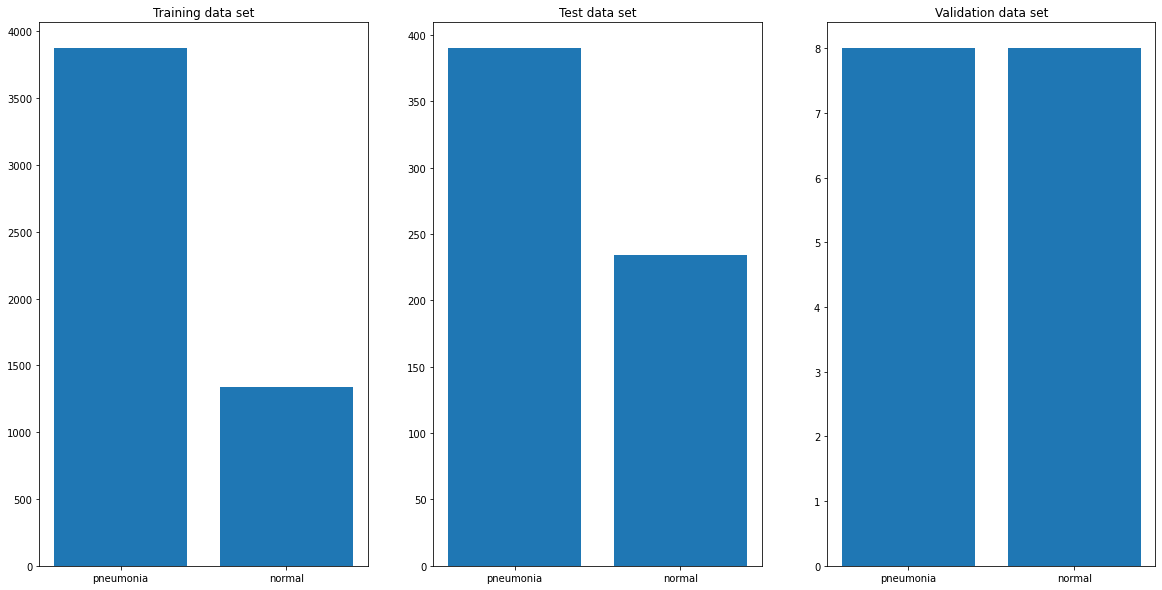

In [ ]:
f = plt.figure(figsize=(20,10))
plt.subplot(1,3,1)
plt.bar(x=["pneumonia","normal"], height = (len(os.listdir(train_dir + "/PNEUMONIA")),len(os.listdir(train_dir + "/NORMAL"))))
plt.title("Training data set")
plt.subplot(1,3,2)
plt.bar(x=["pneumonia","normal"], height = (len(os.listdir(test_dir + "/PNEUMONIA")),len(os.listdir(test_dir + "/NORMAL"))))
plt.title("Test data set")
plt.subplot(1,3,3)
plt.bar(x=["pneumonia","normal"], height = (len(os.listdir(val_dir + "/PNEUMONIA")),len(os.listdir(val_dir + "/NORMAL"))))
plt.title("Validation data set")

<p align='center'> Looking at the result, we can definitely see that <strong>training dataset is imbalanced</strong> when it comes to the target variable. Later on in the project, I will try to apply some of the <strong>data augmentation</strong> techniques to try to balance out the minor class.
</p>

<p align='center'> Let's view some of the images that we're actually dealing with.
</p>

In [ ]:
def view_images(directory,n_of_images):
    plt.figure(figsize=(25,10))
    for i in range(0,n_of_images,2):
        random_label_p = random.choice(range(len(os.listdir(directory + "/PNEUMONIA"))))
        random_label_n = random.choice(range(len(os.listdir(directory + "/NORMAL"))))
        plt.subplot(2,n_of_images // 2, i+1)
        plt.imshow(cv2.imread(os.path.join(directory + "/PNEUMONIA/",os.listdir(directory + "/PNEUMONIA")[random_label_p])))
        plt.title("PNEUMONIA")
        plt.subplot(2,n_of_images // 2, i+2)
        plt.imshow(cv2.imread(os.path.join(directory + "/NORMAL/",os.listdir(directory + "/NORMAL")[random_label_n])))
        plt.title("NORMAL")
        plt.axis("off")
    plt.show()

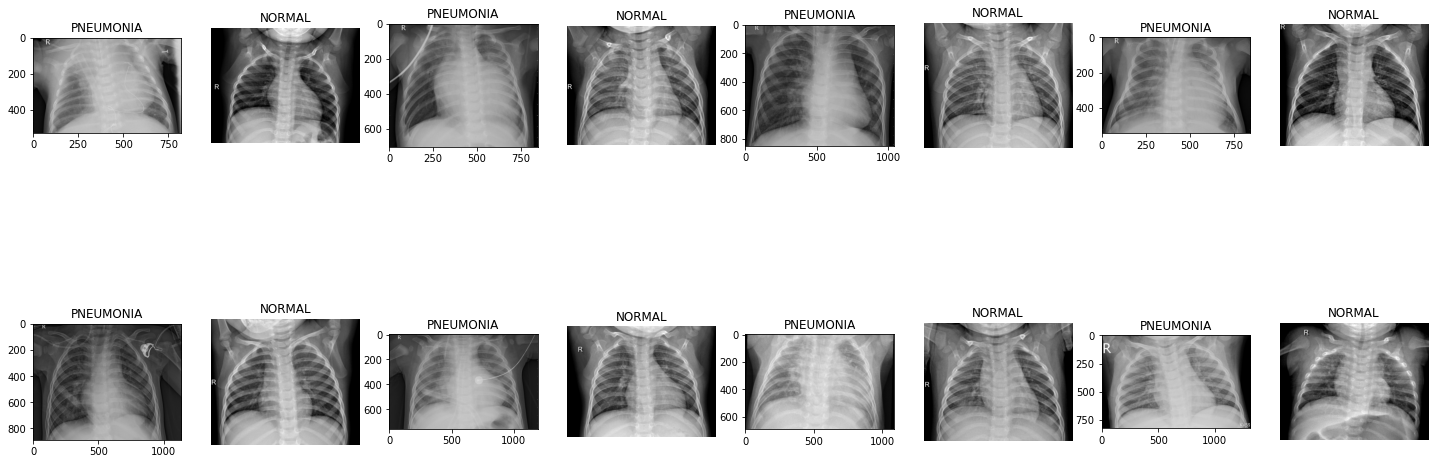

In [ ]:
view_images(train_dir,16)

# **Data Augmentation**

<figure align=center>
  <img src='https://miro.medium.com/max/605/0*Utma-dS47hSoQ6Zt' style='width:100%'>
  <figcaption align='center'> <a href='https://towardsdatascience.com/machinex-image-data-augmentation-using-keras-b459ef87cd22' >Picture 4. Example of the data augmentation techniques. [5] </a> </figcaption>
 </figure>
 <br>
 <br>

 <p align=center><strong>Image data augmentation</strong> is a technique that is used to artificially <strong>expand the dataset</strong>. This can come to the rescue in situations when we are given a dataset with <strong>very few data samples.</strong></p>
<br>
<br>
<p align=center>
Image augmentation parameters that are generally used to increase the data sample are <strong>zooming in and out, shear, rotation</strong> and so on. Usage of these parameters results in the generation of new images during the training of the Deep Learning model. Image samples generated using image augmentation, in general results in the <strong>increase of existing data sample set by nearly 3x to 4x times.</strong> <a href='https://towardsdatascience.com/machinex-image-data-augmentation-using-keras-b459ef87cd22' >[5] </a></p>
<br>
<br>


---



<br>
<p align=center>
To perform the image augmentation on our datasets, I will be using <strong>ImageDataGenerator() class</strong> from <strong>Keras API.</strong> <a href='https://keras.io/api/preprocessing/image/' >[6] </a></p>
<br>


---




In [ ]:
train_data_generator = ImageDataGenerator(
   width_shift_range=0.2,
   height_shift_range=0.2,
   rescale=1./255,
   zoom_range=0.1,
   vertical_flip = True)
val_data_generator = ImageDataGenerator(
   width_shift_range=0.2,
   height_shift_range=0.2,
   rescale=1./255,
   zoom_range=0.1,
   vertical_flip = True)
test_data_generator = ImageDataGenerator(rescale=1./255)
train_generator = train_data_generator.flow_from_directory(
        train_dir,
        target_size=SHAPE_OF_IMAGES,
        color_mode="grayscale",
        batch_size=64,
        class_mode='binary')
validation_generator = val_data_generator.flow_from_directory(
        val_dir,
        color_mode="grayscale",
        target_size=SHAPE_OF_IMAGES,
        batch_size=32,
        class_mode='binary')
test_generator = test_data_generator.flow_from_directory(
        test_dir,
        color_mode="grayscale",
        target_size=SHAPE_OF_IMAGES,
        batch_size=64,
        class_mode='binary')


Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


<p align=center>
When it comes to the image augmentation parameters that I decided to use for this problem, I chose:</p>
<br>


---



1.   Randomly Zoom by 10% some training images
2.   Randomly shift images horizontally by 20% of the width
3.   Randomly shift images vertically by 20% of the height
4.   Randomly flip images vertically.


---



<p align=center><strong>Note:</strong> These are the parameters that resulted in the best results in the further training and evaluating the model. Building the model with different architecture with these parameters might yield slightly different results</p>







# **Building the CNN model**



---


<p align=center>
When it comes to the architecture of the CNN model, I decide to use <strong> two convolutional layers</strong> followed by <strong>dropout layers, batch normalization and max pooling layers using the same padding</strong> to preserve the size of the image within our feature maps. Moving forward, I used the <strong>flatten layer fully connected to the 128 neuron dense layer</strong>. I've also implemented the <strong>L2 regulizer</strong> of the weights and biases since in the past training of the model, it showed some symptoms of overfitting on the training data, even while using dropout layers aswell as image augmentation.
</p>



---

<p align=center>
The value of the <strong> learning rate </strong> used within <strong>the Adam optimizer</strong> has been tuned with the use of keras tuner and has been set to <strong>0.0001.</strong>
</p>


---



In [5]:
model = Sequential([
        Conv2D(filters=32,kernel_size=3,activation = 'relu',padding = 'same', kernel_regularizer=l2(0.005), bias_regularizer=l2(0.005),input_shape = (150,150,1)),
        Dropout(0.25),
        BatchNormalization(),
        MaxPooling2D(padding= 'same'),
        Conv2D(filters=64,kernel_size=3,activation = 'relu',padding = 'same', kernel_regularizer=l2(0.005), bias_regularizer=l2(0.005)),
        Dropout(0.25),
        BatchNormalization(),
        MaxPooling2D(padding= 'same'),
        Flatten(),
        Dense(units = 128,activation= 'relu', kernel_regularizer=l2(0.1), bias_regularizer=l2(0.1)),
        Dropout(0.25),
        BatchNormalization(),
        Dense(1,activation='sigmoid')
])
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.0001),loss = 'binary_crossentropy',metrics=['accuracy'])


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d (Conv2D)              (None, 150, 150, 32)      320       
_________________________________________________________________
dropout (Dropout)            (None, 150, 150, 32)      0         
_________________________________________________________________
batch_normalization (BatchNo (None, 150, 150, 32)      128       
_________________________________________________________________
max_pooling2d (MaxPooling2D) (None, 75, 75, 32)        0         
_________________________________________________________________
conv2d_1 (Conv2D)            (None, 75, 75, 64)        18496     
_________________________________________________________________
dropout_1 (Dropout)          (None, 75, 75, 64)        0         
_________________________________________________________________
batch_normalization_1 (Batch (None, 75, 75, 64)        2



---


<p align=center>
Finally, we're fitting the model that we've built! Here I used <strong>50 epochs</strong>, but what should have been done is to use some of <strong>the callbacks methods</strong> like <strong>EarlyStopping</strong> with the help of Keras to terminate the training whenever the training accuracy stopped improving.
</p>


---



In [ ]:
history = model.fit(train_generator ,epochs = 50, verbose = 1,validation_data=validation_generator)

Epoch 1/50
82/82 [==============================] - 1819s 22s/step - loss: 13.8834 - accuracy: 0.7703 - val_loss: 6.0472 - val_accuracy: 0.5000
Epoch 2/50
82/82 [==============================] - 56s 685ms/step - loss: 3.2892 - accuracy: 0.8365 - val_loss: 2.2914 - val_accuracy: 0.4375
Epoch 3/50
82/82 [==============================] - 56s 682ms/step - loss: 1.4375 - accuracy: 0.8668 - val_loss: 1.5374 - val_accuracy: 0.5625
Epoch 4/50
82/82 [==============================] - 56s 680ms/step - loss: 0.9617 - accuracy: 0.8744 - val_loss: 1.3613 - val_accuracy: 0.4375
Epoch 5/50
82/82 [==============================] - 56s 685ms/step - loss: 0.7967 - accuracy: 0.8794 - val_loss: 1.3016 - val_accuracy: 0.3125
Epoch 6/50
82/82 [==============================] - 56s 684ms/step - loss: 0.7015 - accuracy: 0.8905 - val_loss: 1.4241 - val_accuracy: 0.5000
Epoch 7/50
82/82 [==============================] - 56s 682ms/step - loss: 0.6507 - accuracy: 0.9018 - val_loss: 1.3720 - val_accuracy: 0.500

# **Evaluation the performance of the model**



---


<p align=center>
Let's evaluate the model
</p>


---



In [ ]:
model.evaluate(test_generator)

10/10 [==============================] - 203s 20s/step - loss: 0.6437 - accuracy: 0.8574


[0.6436783075332642, 0.8573718070983887]



---


<p align=center>
Saving the model
</p>


---



In [ ]:
model.save('/content/drive/My Drive/chest_xray/savedmodel.h5')

In [ ]:
model = load_model('/content/drive/My Drive/chest_xray/savedmodel.h5')



---


<p align=center>
Let's plot the performance of our model during the training proccess.
</p>


---



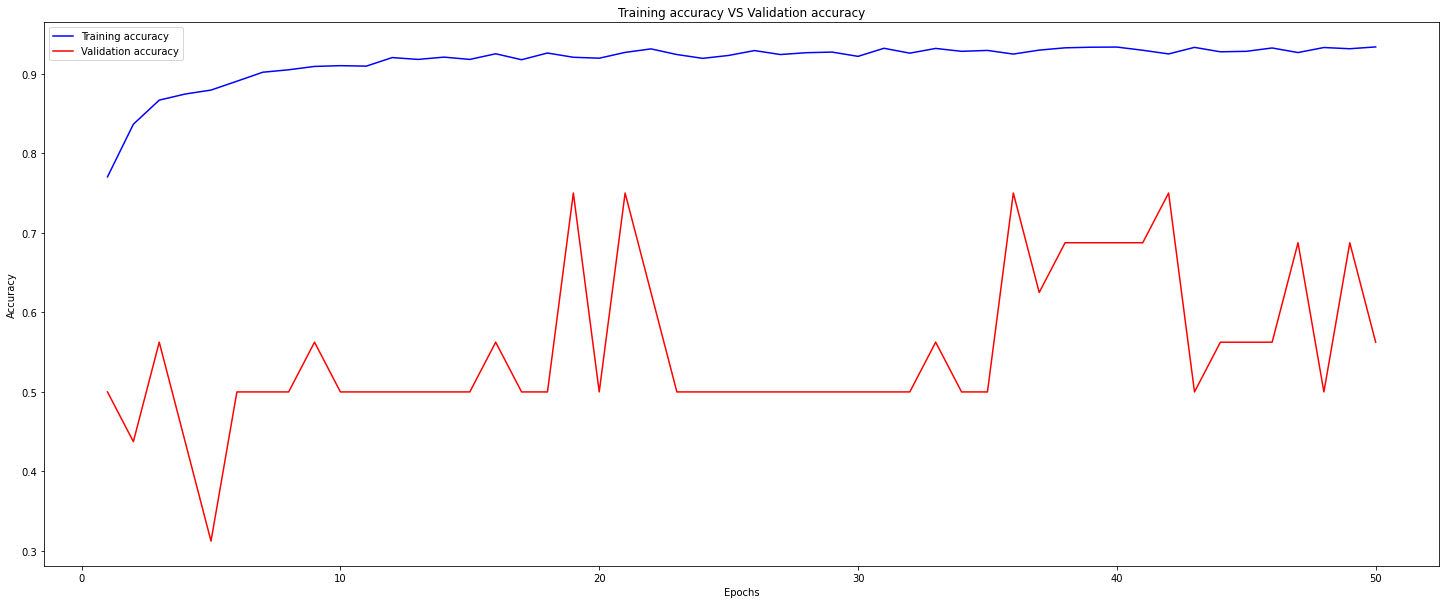

In [ ]:
plt.figure(figsize=(25,10))
plt.plot(range(1,51),history.history['accuracy'],color="blue", label="Training accuracy", linestyle="-")
plt.plot(range(1,51),history.history['val_accuracy'],color="red", label="Validation accuracy", linestyle="-")
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title("Training accuracy VS Validation accuracy")
plt.legend()
plt.show()



---

<p align=center>
The plot doesn't look too good.. The shape of the validation accuracy plot is most likely caused by <strong>insufficient amount of validation data.</strong>
</p>


---



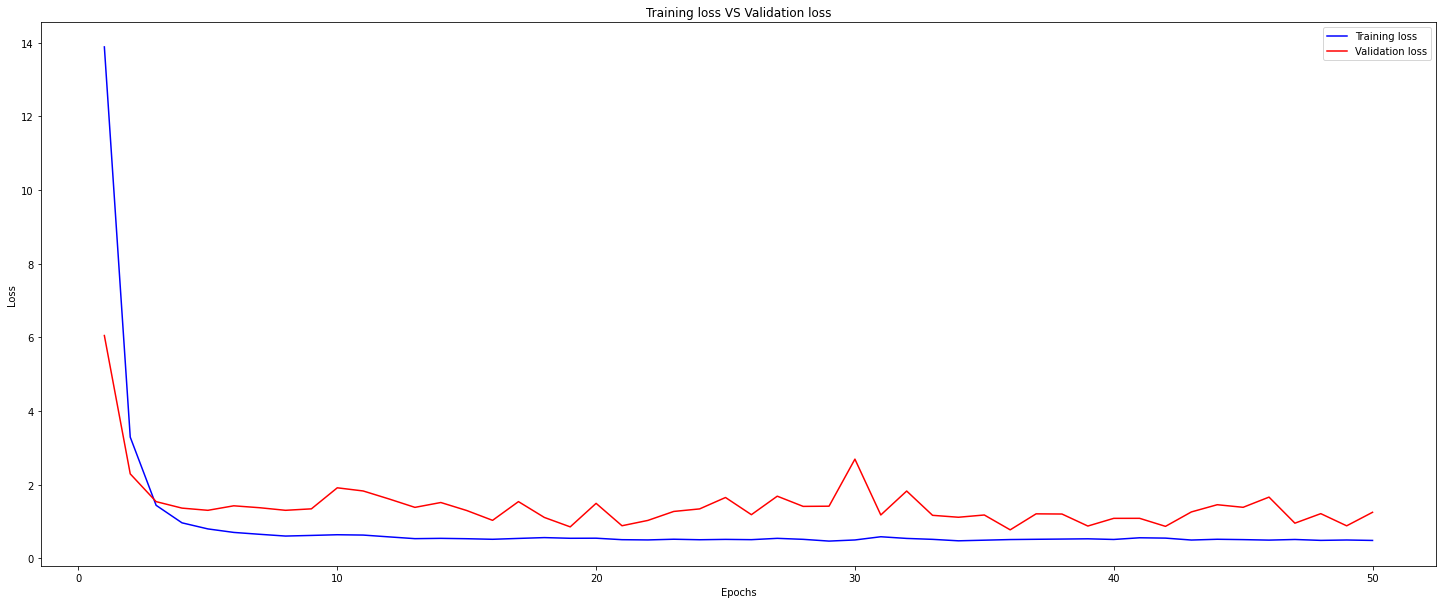

In [ ]:
plt.figure(figsize=(25,10))
plt.plot(range(1,51),history.history['loss'],color="blue", label="Training loss", linestyle="-")
plt.plot(range(1,51),history.history['val_loss'],color="red", label="Validation loss", linestyle="-")
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title("Training loss VS Validation loss")
plt.legend()
plt.show()



---

<p align=center>
Let's dive deeper into the evaluation metrics of our model. To make this proccess much easier, let's transform the data into numpy arrays.
</p>


---



In [ ]:
def get_test_set(directory):
  data = []
  y = []
  for label in ['NORMAL','PNEUMONIA']:
    path = os.path.join(directory, label)
    class_num = ['NORMAL','PNEUMONIA'].index(label)
    for img in os.listdir(path):
        try:
            img_arr = cv2.imread(os.path.join(path, img), cv2.IMREAD_GRAYSCALE)
            resized_arr = cv2.resize(img_arr, SHAPE_OF_IMAGES)
            data.append(resized_arr)
            y.append(class_num)
        except Exception as e:
            print(e)
  return np.array(data),np.array(y)


In [ ]:
X_test,y_test = get_test_set(test_dir)

In [ ]:
X_test = X_test / 255.

In [ ]:
X_test = X_test.reshape(-1,150,150,1)



---

<p align=center>
Classification report:
</p>


---



In [ ]:
y_pred = model.predict_classes(X_test)
print(classification_report(y_test,y_pred))

Instructions for updating:
Please use instead:* `np.argmax(model.predict(x), axis=-1)`,   if your model does multi-class classification   (e.g. if it uses a `softmax` last-layer activation).* `(model.predict(x) > 0.5).astype("int32")`,   if your model does binary classification   (e.g. if it uses a `sigmoid` last-layer activation).
              precision    recall  f1-score   support

           0       0.83      0.79      0.81       234
           1       0.88      0.90      0.89       390

    accuracy                           0.86       624
   macro avg       0.85      0.85      0.85       624
weighted avg       0.86      0.86      0.86       624





---

<p align=center>
Confusion matrix:
</p>


---



In [ ]:
cm = confusion_matrix(y_test,y_pred)
cm

array([[185,  49],
       [ 38, 352]])

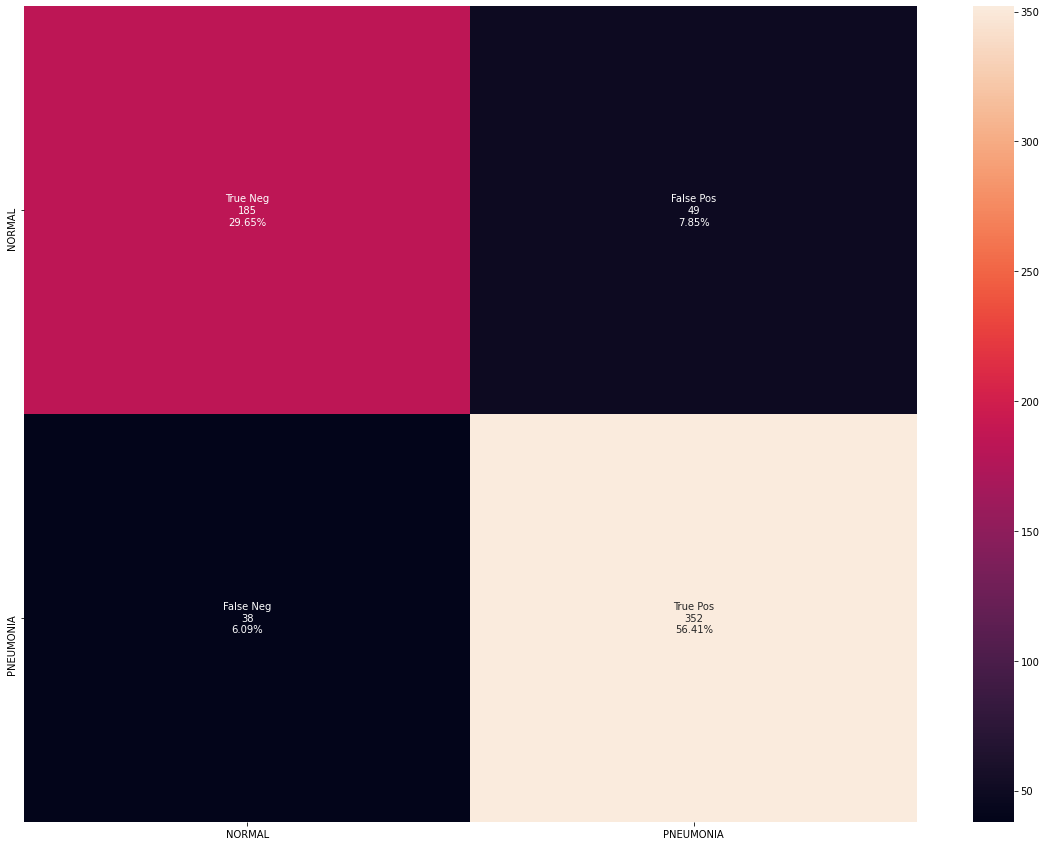

In [ ]:
import seaborn as sns
plt.figure(figsize=(20,15))
group_names = ['True Neg','False Pos','False Neg','True Pos']
group_counts = ['{0:0.0f}'.format(value) for value in
                cm.flatten()]
group_percentages = ['{0:.2%}'.format(value) for value in
                     cm.flatten()/np.sum(cm)]
labels = [f'{v1}\n{v2}\n{v3}' for v1, v2, v3 in
          zip(group_names,group_counts,group_percentages)]
labels = np.asarray(labels).reshape(2,2)
sns.heatmap(cm, annot=labels, fmt='',xticklabels=['NORMAL','PNEUMONIA'],yticklabels=['NORMAL','PNEUMONIA'])



---

<p align=center>
ROC AUC curve:
</p>

---



In [ ]:
def plot_roc_auc_curve(model,X,y):

  y_score = model.predict_classes(X)

  fpr, tpr, thresholds = roc_curve(y, y_score)

  fig = px.area(
      x=fpr, y=tpr,
      title=f'ROC Curve (AUC={auc(fpr, tpr):.4f})',
      labels=dict(x='False Positive Rate', y='True Positive Rate'),
      width=1400, height=700
  )
  fig.add_shape(
      type='line', line=dict(dash='dash'),
      x0=0, x1=1, y0=0, y1=1
  )

  fig.update_yaxes(scaleanchor="x", scaleratio=1)
  fig.update_xaxes(constrain='domain')

  fig.show(renderer="notebook_connected")

In [ ]:
plot_roc_auc_curve(model,X_test,y_test)

# **Summary of the results**



---




*   Accuracy of the model: <strong> 86 % </strong>
*   Precision score of the model : <strong> 88 % </strong>
*   Recall score of the model: <strong> 90% </strong>
*   AUC score of the model: <strong> 0,85 </strong>





---



# **What's next?**



---

<p align=center>
Overall, I think that I was able to achieve pretty good results through building and tuning the model. Although, I do think that there are a some aspects that could have yielded a better result at the end of the day. <br>


---


Some of these techniques are:


*   Implementing some of the transfer learning techniques instead of creating the architecture of the CNN model "from scratch".
*   Gathering more data; especially when it comes to the lung of photos of people not suffering from pneumonia.
*   Further parameter tuning in terms of the number of feature maps in each of the convolutional layer; general extensive hypertuning of the model parameters.



---




# **ResNet50 (comparison)**

In [ ]:
resnet = keras.applications.ResNet50(
    input_shape = (150,150,3),
    include_top = False

)

In [ ]:
for layer in resnet.layers:
    layer.trainable = False

In [ ]:
for layer in resnet.layers:
    if "BatchNormalization" in layer.__class__.__name__:
        layer.trainable = True

In [ ]:
x = Flatten()(resnet.output)
x = Dense(1024,activation="relu")(x)
x = Dropout(0.5)(x)
x = BatchNormalization()(x)
x = Dense(1,activation="sigmoid")(x)
model = Model(inputs = resnet.input,outputs = x)

In [ ]:
model.summary()

Model: "functional_1"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_1 (InputLayer)            [(None, 150, 150, 3) 0                                            
__________________________________________________________________________________________________
conv1_pad (ZeroPadding2D)       (None, 156, 156, 3)  0           input_1[0][0]                    
__________________________________________________________________________________________________
conv1_conv (Conv2D)             (None, 75, 75, 64)   9472        conv1_pad[0][0]                  
__________________________________________________________________________________________________
conv1_bn (BatchNormalization)   (None, 75, 75, 64)   256         conv1_conv[0][0]                 
_______________________________________________________________________________________

In [6]:
model.compile(optimizer="adam",loss="binary_crossentropy", metrics = ["accuracy"])

In [4]:
from keras.models import Sequential
from keras.layers import (
    Conv2D, Dropout, BatchNormalization,
    MaxPooling2D, Flatten, Dense
)
from keras.regularizers import l2
import keras

In [7]:
print("Model created and compiled successfully.")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
model.summary()

Model created and compiled successfully.
Input shape: (None, 150, 150, 1)
Output shape: (None, 1)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 150, 150, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 38, 38, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 92416)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,829,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,849,217 (45.20 MB)

 Trainable params: 11,848,769 (45.20 MB)

 Non-trainable params: 448 (1.75 KB)

In [8]:
from pathlib import Path

for path in [
    Path("/content/chest_xray"),
    Path("/content/pneumonia_data/chest_xray"),
    Path("/content/drive/MyDrive/chest_xray"),
]:
    print(("FOUND  " if path.exists() else "MISSING") + str(path))

MISSING/content/chest_xray
MISSING/content/pneumonia_data/chest_xray
MISSING/content/drive/MyDrive/chest_xray


In [9]:
import getpass
import os

os.environ["KAGGLE_API_TOKEN"] = getpass.getpass(
    "Enter your NEW Kaggle token (input is hidden): "
)

print("Token loaded into this session.")

Enter your NEW Kaggle token (input is hidden): ··········
Token loaded into this session.


In [10]:
%pip install -q -U kaggle

In [11]:
!kaggle --version

Kaggle CLI 2.2.5


In [12]:
%pip install -q -U kaggle

In [13]:
import os
import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass.getpass(
    "Enter your NEW Kaggle token: "
)

print("Token loaded for this session.")

Enter your NEW Kaggle token: ··········
Token loaded for this session.


In [14]:
!kaggle --version

Kaggle CLI 2.2.5


In [15]:
!kaggle datasets list -s chest-xray-pneumonia

ref                                                             title                                                      size  lastUpdated                 downloadCount  voteCount  usabilityRating  
--------------------------------------------------------------  --------------------------------------------------  -----------  --------------------------  -------------  ---------  ---------------  
divyam6969/chest-xray-pneumonia-dataset                         Chest XRAY - Pneumonia Dataset                       1151535496  2024-01-17 12:19:16.570000           1573         30  0.6875           
kostasdiamantaras/chest-xrays-bacterial-viral-pneumonia-normal  Chest Xrays: bacterial / viral pneumonia / normal    1222999548  2020-10-27 16:51:15.783000           6329         22  0.7058824        
amanullahasraf/covid19-pneumonia-normal-chest-xray-pa-dataset   COVID19_Pneumonia_Normal_Chest_Xray_PA_Dataset       2053474983  2020-07-13 05:54:22.483000           4461         36  0.8125       

In [16]:
from pathlib import Path

DATA_DIR = Path("/content/pneumonia_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia -p /content/pneumonia_data

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [01:47<00:00, 22.9MB/s]



In [17]:
import zipfile

zip_files = list(DATA_DIR.glob("*.zip"))

if not zip_files:
    raise FileNotFoundError(
        "Dataset ZIP not found. Check the download cell."
    )

for zip_path in zip_files:
    print("Extracting:", zip_path.name)
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(DATA_DIR)

print("Dataset extraction complete.")

Extracting: chest-xray-pneumonia.zip
Dataset extraction complete.


In [18]:
from pathlib import Path

for split in ["train", "test", "val"]:
    folders = list(DATA_DIR.rglob(split))
    for folder in folders:
        if folder.is_dir() and all(
            (folder / cls).is_dir()
            for cls in ["NORMAL", "PNEUMONIA"]
        ):
            print(f"\n{split.upper()}: {folder}")
            for cls in ["NORMAL", "PNEUMONIA"]:
                count = sum(
                    1 for f in (folder / cls).iterdir()
                    if f.is_file()
                )
                print(f"  {cls}: {count} files")


TRAIN: /content/pneumonia_data/chest_xray/train
  NORMAL: 1341 files
  PNEUMONIA: 3875 files

TRAIN: /content/pneumonia_data/chest_xray/chest_xray/train
  NORMAL: 1342 files
  PNEUMONIA: 3876 files

TRAIN: /content/pneumonia_data/chest_xray/__MACOSX/chest_xray/train
  NORMAL: 1342 files
  PNEUMONIA: 3876 files

TEST: /content/pneumonia_data/chest_xray/test
  NORMAL: 234 files
  PNEUMONIA: 390 files

TEST: /content/pneumonia_data/chest_xray/chest_xray/test
  NORMAL: 234 files
  PNEUMONIA: 390 files

TEST: /content/pneumonia_data/chest_xray/__MACOSX/chest_xray/test
  NORMAL: 234 files
  PNEUMONIA: 390 files

VAL: /content/pneumonia_data/chest_xray/val
  NORMAL: 8 files
  PNEUMONIA: 8 files

VAL: /content/pneumonia_data/chest_xray/chest_xray/val
  NORMAL: 9 files
  PNEUMONIA: 9 files

VAL: /content/pneumonia_data/chest_xray/__MACOSX/chest_xray/val
  NORMAL: 9 files
  PNEUMONIA: 9 files


In [19]:
from pathlib import Path

root = Path("/content/pneumonia_data")

matches = []
for path in root.rglob("*"):
    if path.is_dir() and path.name == "train":
        if (path / "NORMAL").is_dir() and (path / "PNEUMONIA").is_dir():
            matches.append(path)

if matches:
    print("Dataset is ready!")
    for path in matches:
        print("Training folder:", path)
else:
    print("Dataset not found in the expected structure.")
    print("Check whether the download and extraction completed.")

Dataset is ready!
Training folder: /content/pneumonia_data/chest_xray/train
Training folder: /content/pneumonia_data/chest_xray/chest_xray/train
Training folder: /content/pneumonia_data/chest_xray/__MACOSX/chest_xray/train


In [20]:
from pathlib import Path

root = Path("/content/pneumonia_data")
matches = []

for path in root.rglob("train"):
    if path.is_dir() and all(
        (path / cls).is_dir()
        for cls in ["NORMAL", "PNEUMONIA"]
    ):
        matches.append(path)

if matches:
    print("DATASET READY")
    for path in matches:
        print("Training folder:", path)
else:
    print("DATASET NOT FOUND — download or extraction may have failed.")

DATASET READY
Training folder: /content/pneumonia_data/chest_xray/train
Training folder: /content/pneumonia_data/chest_xray/chest_xray/train
Training folder: /content/pneumonia_data/chest_xray/__MACOSX/chest_xray/train


In [21]:
from pathlib import Path

DATA_DIR = Path("/content/pneumonia_data")

TRAIN_DIR = next(
    p for p in DATA_DIR.rglob("train")
    if p.is_dir()
    and (p / "NORMAL").is_dir()
    and (p / "PNEUMONIA").is_dir()
)

DATASET_ROOT = TRAIN_DIR.parent
TEST_DIR = DATASET_ROOT / "test"
VAL_DIR = DATASET_ROOT / "val"

print("Train:", TRAIN_DIR, TRAIN_DIR.exists())
print("Test:", TEST_DIR, TEST_DIR.exists())
print("Validation:", VAL_DIR, VAL_DIR.exists())

Train: /content/pneumonia_data/chest_xray/train True
Test: /content/pneumonia_data/chest_xray/test True
Validation: /content/pneumonia_data/chest_xray/val True


In [22]:
for split_name, split_dir in [
    ("TRAIN", TRAIN_DIR),
    ("VALIDATION", VAL_DIR),
    ("TEST", TEST_DIR)
]:
    print(f"\n{split_name}")

    if not split_dir.exists():
        print("Folder missing")
        continue

    for cls in ["NORMAL", "PNEUMONIA"]:
        folder = split_dir / cls
        count = sum(1 for f in folder.iterdir() if f.is_file()) if folder.exists() else 0
        print(f"{cls}: {count} images")


TRAIN
NORMAL: 1341 images
PNEUMONIA: 3875 images

VALIDATION
NORMAL: 8 images
PNEUMONIA: 8 images

TEST
NORMAL: 234 images
PNEUMONIA: 390 images


In [23]:
from pathlib import Path

DATA_DIR = Path("/content/pneumonia_data")

train_matches = [
    p for p in DATA_DIR.rglob("train")
    if p.is_dir()
    and (p / "NORMAL").is_dir()
    and (p / "PNEUMONIA").is_dir()
]

if not train_matches:
    raise FileNotFoundError(
        "Dataset not found. Download and extract it before continuing."
    )

TRAIN_DIR = train_matches[0]
DATASET_ROOT = TRAIN_DIR.parent
VAL_DIR = DATASET_ROOT / "val"
TEST_DIR = DATASET_ROOT / "test"

print("Train:", TRAIN_DIR)
print("Validation:", VAL_DIR, "| Exists:", VAL_DIR.exists())
print("Test:", TEST_DIR, "| Exists:", TEST_DIR.exists())

Train: /content/pneumonia_data/chest_xray/train
Validation: /content/pneumonia_data/chest_xray/val | Exists: True
Test: /content/pneumonia_data/chest_xray/test | Exists: True


In [24]:
for split_name, split_dir in [
    ("TRAIN", TRAIN_DIR),
    ("VALIDATION", VAL_DIR),
    ("TEST", TEST_DIR)
]:
    print(f"\n{split_name}")

    if not split_dir.exists():
        print("Folder missing")
        continue

    for cls in ["NORMAL", "PNEUMONIA"]:
        folder = split_dir / cls
        count = (
            sum(1 for f in folder.iterdir() if f.is_file())
            if folder.exists() else 0
        )
        print(f"{cls}: {count}")


TRAIN
NORMAL: 1341
PNEUMONIA: 3875

VALIDATION
NORMAL: 8
PNEUMONIA: 8

TEST
NORMAL: 234
PNEUMONIA: 390


In [25]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score
)

SEED = 42
IMG_SIZE = (150, 150)
BATCH_SIZE = 32

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [26]:
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=7,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.08,
    horizontal_flip=True
)

eval_datagen = ImageDataGenerator(rescale=1.0 / 255)

train_generator = train_datagen.flow_from_directory(
    str(TRAIN_DIR),
    target_size=IMG_SIZE,
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=True,
    seed=SEED
)

val_generator = eval_datagen.flow_from_directory(
    str(VAL_DIR),
    target_size=IMG_SIZE,
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

test_generator = eval_datagen.flow_from_directory(
    str(TEST_DIR),
    target_size=IMG_SIZE,
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

print("\nClass mapping:", train_generator.class_indices)

Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.

Class mapping: {'NORMAL': 0, 'PNEUMONIA': 1}


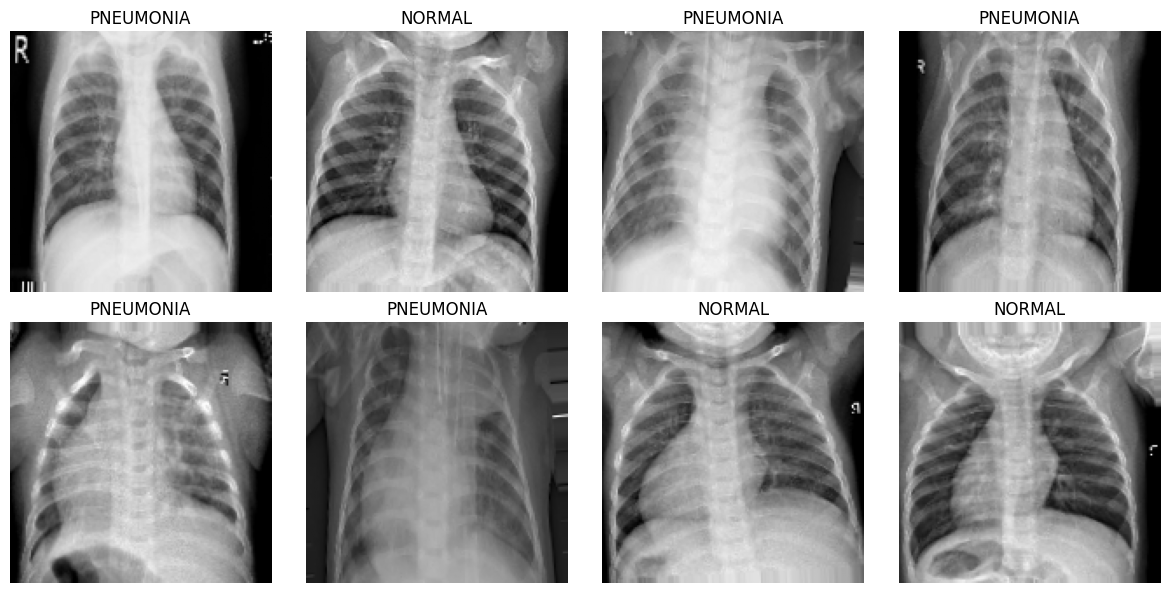

Image batch shape: (32, 150, 150, 1)
Label batch shape: (32,)


In [27]:
images, labels = next(train_generator)

plt.figure(figsize=(12, 6))

for i in range(min(8, len(images))):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    label = "PNEUMONIA" if int(labels[i]) == 1 else "NORMAL"
    plt.title(label)
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

In [28]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Flatten, Dense,
    Dropout, BatchNormalization
)
from tensorflow.keras.regularizers import l2

model = Sequential([
    keras.Input(shape=(150, 150, 1)),

    Conv2D(32, 3, activation="relu", padding="same",
           kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    MaxPooling2D(pool_size=2),
    Dropout(0.20),

    Conv2D(64, 3, activation="relu", padding="same",
           kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    MaxPooling2D(pool_size=2),
    Dropout(0.25),

    Conv2D(128, 3, activation="relu", padding="same",
           kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    MaxPooling2D(pool_size=2),
    Dropout(0.25),

    Flatten(),
    Dense(128, activation="relu", kernel_regularizer=l2(0.001)),
    Dropout(0.40),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="auc")
    ]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 150, 150, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 37, 37, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     5,308,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,402,241 (20.61 MB)

 Trainable params: 5,401,793 (20.61 MB)

 Non-trainable params: 448 (1.75 KB)

In [29]:
from pathlib import Path

OUTPUT_DIR = Path("/content/pneumonia_project")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        str(OUTPUT_DIR / "best_pneumonia_cnn.keras"),
        monitor="val_auc",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("Callbacks ready.")
print("Model output:", OUTPUT_DIR)

Callbacks ready.
Model output: /content/pneumonia_project


In [30]:
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=15,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 330ms/step - accuracy: 0.8387 - auc: 0.8667 - loss: 0.8699
Epoch 1: val_auc improved from None to 0.50000, saving model to /content/pneumonia_project/best_pneumonia_cnn.keras

Epoch 1: finished saving model to /content/pneumonia_project/best_pneumonia_cnn.keras
163/163 ━━━━━━━━━━━━━━━━━━━━ 72s 347ms/step - accuracy: 0.8900 - auc: 0.9342 - loss: 0.6830 - val_accuracy: 0.5000 - val_auc: 0.5000 - val_loss: 10.3480 - learning_rate: 1.0000e-04
Epoch 2/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 269ms/step - accuracy: 0.9407 - auc: 0.9762 - loss: 0.5325
Epoch 2: val_auc did not improve from 0.50000
163/163 ━━━━━━━━━━━━━━━━━━━━ 44s 270ms/step - accuracy: 0.9365 - auc: 0.9744 - loss: 0.5339 - val_accuracy: 0.5000 - val_auc: 0.5000 - val_loss: 16.5241 - learning_rate: 1.0000e-04
Epoch 3/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 270ms/step - accuracy: 0.9343 - auc: 0.9752 - loss: 0.5151
Epoch 3: val_auc did not improve from 0.50000

Epoch 3: ReduceLROnPlateau reducing 

In [31]:
import tensorflow as tf
from pathlib import Path

OUTPUT_DIR = Path("/content/pneumonia_project")
MODEL_PATH = OUTPUT_DIR / "best_pneumonia_cnn.keras"

model = tf.keras.models.load_model(MODEL_PATH)

print("Best checkpoint loaded:", MODEL_PATH.exists())
print("Test images:", test_generator.samples)

test_generator.reset()

test_results = model.evaluate(test_generator, verbose=1, return_dict=True)

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

Best checkpoint loaded: True
Test images: 624
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 172ms/step - accuracy: 0.8766 - auc: 0.9298 - loss: 0.7534
accuracy: 0.8766
auc: 0.9298
loss: 0.7534


In [32]:
import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

test_generator.reset()

y_true = test_generator.classes
y_prob = model.predict(test_generator, verbose=1).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Class mapping:", test_generator.class_indices)
print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["NORMAL", "PNEUMONIA"],
    zero_division=0,
    digits=4
))

print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_true, y_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_true, y_pred, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_true, y_prob), 4))

20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 158ms/step
Class mapping: {'NORMAL': 0, 'PNEUMONIA': 1}

Classification Report:

              precision    recall  f1-score   support

      NORMAL     0.8489    0.8162    0.8322       234
   PNEUMONIA     0.8922    0.9128    0.9024       390

    accuracy                         0.8766       624
   macro avg     0.8706    0.8645    0.8673       624
weighted avg     0.8760    0.8766    0.8761       624

Accuracy : 0.8766
Precision: 0.8922
Recall   : 0.9128
F1-score : 0.9024
ROC-AUC  : 0.9391


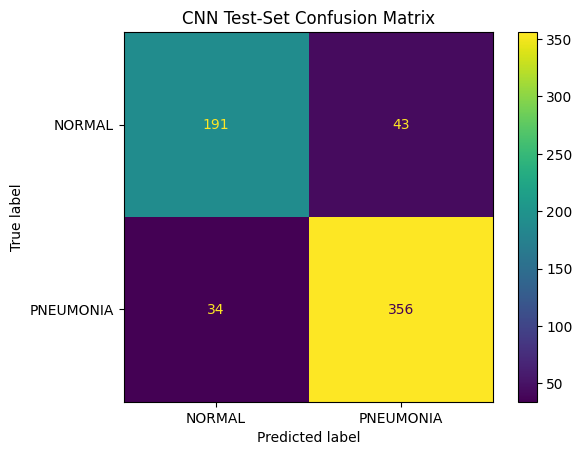

True negatives : 191
False positives: 43
False negatives: 34
True positives : 356


In [33]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NORMAL", "PNEUMONIA"]
)

display.plot(values_format="d")
plt.title("CNN Test-Set Confusion Matrix")
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True negatives :", tn)
print("False positives:", fp)
print("False negatives:", fn)
print("True positives :", tp)

In [34]:
from sklearn.metrics import accuracy_score, roc_auc_score

test_generator.reset()

x_test = []
y_test = []

for batch_x, batch_y in test_generator:
    x_test.append(batch_x)
    y_test.append(batch_y)

    if len(y_test) * BATCH_SIZE >= test_generator.samples:
        break

x_test = np.concatenate(x_test, axis=0)[:test_generator.samples]
y_test = np.concatenate(y_test, axis=0)[:test_generator.samples].astype(int)

# Original images
p_original = model.predict(x_test, batch_size=BATCH_SIZE, verbose=1).ravel()

# Mild brightness changes, clipped to the valid rescaled image range
x_bright = np.clip(x_test * 1.15, 0.0, 1.0)
x_dim = np.clip(x_test * 0.85, 0.0, 1.0)

p_bright = model.predict(x_bright, batch_size=BATCH_SIZE, verbose=1).ravel()
p_dim = model.predict(x_dim, batch_size=BATCH_SIZE, verbose=1).ravel()

def report_metrics(name, labels, probabilities):
    predictions = (probabilities >= 0.5).astype(int)
    print(
        f"{name:20s} | "
        f"Accuracy: {accuracy_score(labels, predictions):.4f} | "
        f"AUC: {roc_auc_score(labels, probabilities):.4f}"
    )

report_metrics("Original", y_test, p_original)
report_metrics("Brightness +15%", y_test, p_bright)
report_metrics("Brightness -15%", y_test, p_dim)

20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
Original             | Accuracy: 0.8766 | AUC: 0.9391
Brightness +15%      | Accuracy: 0.8686 | AUC: 0.9284
Brightness -15%      | Accuracy: 0.8381 | AUC: 0.9400


In [36]:
import pandas as pd
import json
from IPython.display import display

experiment_results = []

for name, probabilities in [
    ("original", p_original),
    ("brightness_plus_15_percent", p_bright),
    ("brightness_minus_15_percent", p_dim)
]:
    predictions = (probabilities >= 0.5).astype(int)

    experiment_results.append({
        "condition": name,
        "accuracy": float(accuracy_score(y_test, predictions)),
        "roc_auc": float(roc_auc_score(y_test, probabilities)),
        "precision": float(precision_score(y_test, predictions, zero_division=0)),
        "recall": float(recall_score(y_test, predictions, zero_division=0)),
        "f1_score": float(f1_score(y_test, predictions, zero_division=0))
    })

results_df = pd.DataFrame(experiment_results)

results_path = OUTPUT_DIR / "brightness_robustness_results.csv"
results_df.to_csv(results_path, index=False)

display(results_df)
print("Saved to:", results_path)

,condition,accuracy,roc_auc,precision,recall,f1_score
0,original,0.876603,0.939119,0.892231,0.912821,0.902408
1,brightness_plus_15_percent,0.868590,0.928375,0.909574,0.876923,0.892950
2,brightness_minus_15_percent,0.838141,0.940001,0.806794,0.974359,0.882695


Saved to: /content/pneumonia_project/brightness_robustness_results.csv


In [37]:
import numpy as np
import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path("/content/pneumonia_project")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Preserve the baseline model and its test results
baseline_model = model
baseline_probabilities = p_original.copy()
baseline_labels = y_test.copy()

baseline_predictions = (baseline_probabilities >= 0.5).astype(int)

print("Baseline model preserved.")
print("Test images:", len(baseline_labels))

Baseline model preserved.
Test images: 624


In [38]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

SEED = 42
IMG_SIZE = (150, 150)
BATCH_SIZE = 32

split_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    validation_split=0.15,
    rotation_range=7,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.08,
    brightness_range=(0.85, 1.15),
    horizontal_flip=True
)

robust_train_generator = split_datagen.flow_from_directory(
    str(TRAIN_DIR),
    target_size=IMG_SIZE,
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="training",
    shuffle=True,
    seed=SEED
)

# Validation images are not augmented.
validation_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    validation_split=0.15
)

robust_val_generator = validation_datagen.flow_from_directory(
    str(TRAIN_DIR),
    target_size=IMG_SIZE,
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="validation",
    shuffle=False,
    seed=SEED
)

print("Training images:", robust_train_generator.samples)
print("Validation images:", robust_val_generator.samples)
print("Class mapping:", robust_train_generator.class_indices)

Found 4434 images belonging to 2 classes.
Found 782 images belonging to 2 classes.
Training images: 4434
Validation images: 782
Class mapping: {'NORMAL': 0, 'PNEUMONIA': 1}


In [39]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

def build_pneumonia_cnn():
    model = keras.Sequential([
        keras.Input(shape=(150, 150, 1)),

        layers.Conv2D(
            32, 3, padding="same", activation="relu",
            kernel_regularizer=regularizers.l2(0.001)
        ),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),
        layers.Dropout(0.20),

        layers.Conv2D(
            64, 3, padding="same", activation="relu",
            kernel_regularizer=regularizers.l2(0.001)
        ),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),
        layers.Dropout(0.25),

        layers.Conv2D(
            128, 3, padding="same", activation="relu",
            kernel_regularizer=regularizers.l2(0.001)
        ),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),
        layers.Dropout(0.25),

        layers.Flatten(),
        layers.Dense(
            128, activation="relu",
            kernel_regularizer=regularizers.l2(0.001)
        ),
        layers.Dropout(0.40),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.0001),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(name="auc")]
    )

    return model

robust_model = build_pneumonia_cnn()
robust_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 150, 150, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 37, 37, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     5,308,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,402,241 (20.61 MB)

 Trainable params: 5,401,793 (20.61 MB)

 Non-trainable params: 448 (1.75 KB)

In [40]:
robust_callbacks = [
    keras.callbacks.ModelCheckpoint(
        str(OUTPUT_DIR / "brightness_robust_cnn.keras"),
        monitor="val_auc",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

robust_history = robust_model.fit(
    robust_train_generator,
    validation_data=robust_val_generator,
    epochs=15,
    callbacks=robust_callbacks,
    verbose=1
)

Epoch 1/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 375ms/step - accuracy: 0.8216 - auc: 0.8144 - loss: 0.9517
Epoch 1: val_auc improved from None to 0.50000, saving model to /content/pneumonia_project/brightness_robust_cnn.keras

Epoch 1: finished saving model to /content/pneumonia_project/brightness_robust_cnn.keras
139/139 ━━━━━━━━━━━━━━━━━━━━ 69s 437ms/step - accuracy: 0.8703 - auc: 0.9033 - loss: 0.7450 - val_accuracy: 0.7430 - val_auc: 0.5000 - val_loss: 3.2937 - learning_rate: 1.0000e-04
Epoch 2/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 272ms/step - accuracy: 0.9160 - auc: 0.9624 - loss: 0.5847
Epoch 2: val_auc did not improve from 0.50000
139/139 ━━━━━━━━━━━━━━━━━━━━ 43s 307ms/step - accuracy: 0.9175 - auc: 0.9647 - loss: 0.5740 - val_accuracy: 0.7430 - val_auc: 0.5000 - val_loss: 5.5020 - learning_rate: 1.0000e-04
Epoch 3/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 268ms/step - accuracy: 0.9303 - auc: 0.9709 - loss: 0.5459
Epoch 3: val_auc improved from 0.50000 to 0.50995, saving model to /content/pne

In [41]:
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score,
    recall_score, f1_score
)

robust_model = keras.models.load_model(
    str(OUTPUT_DIR / "brightness_robust_cnn.keras")
)

# Reuse the exact same test images and labels.
robust_probabilities = robust_model.predict(
    x_test, batch_size=BATCH_SIZE, verbose=1
).ravel()

def calculate_metrics(labels, probabilities):
    predictions = (probabilities >= 0.5).astype(int)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision_score(labels, predictions, zero_division=0),
        "recall": recall_score(labels, predictions, zero_division=0),
        "f1_score": f1_score(labels, predictions, zero_division=0),
        "roc_auc": roc_auc_score(labels, probabilities)
    }

baseline_metrics = calculate_metrics(
    baseline_labels, baseline_probabilities
)

robust_metrics = calculate_metrics(
    y_test, robust_probabilities
)

comparison = pd.DataFrame(
    [baseline_metrics, robust_metrics],
    index=["Baseline CNN", "Brightness-Augmented CNN"]
)

display(comparison.round(4))

20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step


,accuracy,precision,recall,f1_score,roc_auc
Baseline CNN,0.8766,0.8922,0.9128,0.9024,0.9391
Brightness-Augmented CNN,0.8510,0.8235,0.9692,0.8905,0.9543


In [42]:
conditions = {
    "Original": x_test,
    "Brightness +15%": np.clip(x_test * 1.15, 0, 1),
    "Brightness -15%": np.clip(x_test * 0.85, 0, 1)
}

rows = []

for condition, images in conditions.items():
    baseline_p = baseline_model.predict(
        images, batch_size=BATCH_SIZE, verbose=0
    ).ravel()

    robust_p = robust_model.predict(
        images, batch_size=BATCH_SIZE, verbose=0
    ).ravel()

    for model_name, probabilities in [
        ("Baseline CNN", baseline_p),
        ("Brightness-Augmented CNN", robust_p)
    ]:
        metrics = calculate_metrics(y_test, probabilities)
        rows.append({"condition": condition, "model": model_name, **metrics})

robustness_comparison = pd.DataFrame(rows)
display(robustness_comparison.round(4))

robustness_comparison.to_csv(
    OUTPUT_DIR / "baseline_vs_brightness_augmentation.csv",
    index=False
)

print("Comparison saved.")

,condition,model,accuracy,precision,recall,f1_score,roc_auc
0,Original,Baseline CNN,0.8766,0.8922,0.9128,0.9024,0.9391
1,Original,Brightness-Augmented CNN,0.8510,0.8235,0.9692,0.8905,0.9543
2,Brightness +15%,Baseline CNN,0.8686,0.9096,0.8769,0.8930,0.9284
3,Brightness +15%,Brightness-Augmented CNN,0.8462,0.8196,0.9667,0.8871,0.9488
4,Brightness -15%,Baseline CNN,0.8381,0.8068,0.9744,0.8827,0.9400
5,Brightness -15%,Brightness-Augmented CNN,0.8173,0.7805,0.9846,0.8707,0.9559


Comparison saved.


In [43]:
import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path("/content/pneumonia_project")

comparison_rows = []

for condition, images in conditions.items():
    for model_name, current_model in [
        ("Baseline CNN", baseline_model),
        ("Brightness-Augmented CNN", robust_model)
    ]:
        probabilities = current_model.predict(
            images, batch_size=BATCH_SIZE, verbose=0
        ).ravel()

        metrics = calculate_metrics(y_test, probabilities)

        comparison_rows.append({
            "condition": condition,
            "model": model_name,
            **metrics
        })

final_comparison = pd.DataFrame(comparison_rows)
display(final_comparison.round(4))

final_comparison.to_csv(
    OUTPUT_DIR / "complete_robustness_report.csv",
    index=False
)

print("Saved:", OUTPUT_DIR / "complete_robustness_report.csv")

,condition,model,accuracy,precision,recall,f1_score,roc_auc
0,Original,Baseline CNN,0.8766,0.8922,0.9128,0.9024,0.9391
1,Original,Brightness-Augmented CNN,0.8510,0.8235,0.9692,0.8905,0.9543
2,Brightness +15%,Baseline CNN,0.8686,0.9096,0.8769,0.8930,0.9284
3,Brightness +15%,Brightness-Augmented CNN,0.8462,0.8196,0.9667,0.8871,0.9488
4,Brightness -15%,Baseline CNN,0.8381,0.8068,0.9744,0.8827,0.9400
5,Brightness -15%,Brightness-Augmented CNN,0.8173,0.7805,0.9846,0.8707,0.9559


Saved: /content/pneumonia_project/complete_robustness_report.csv


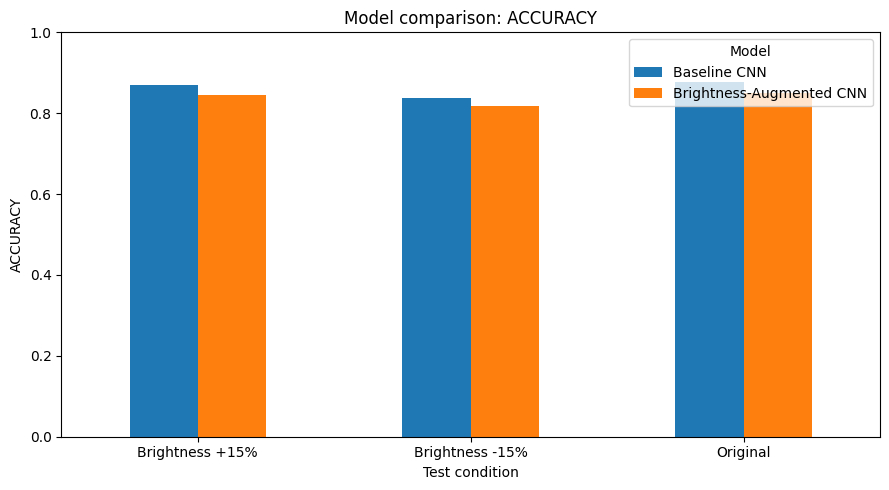

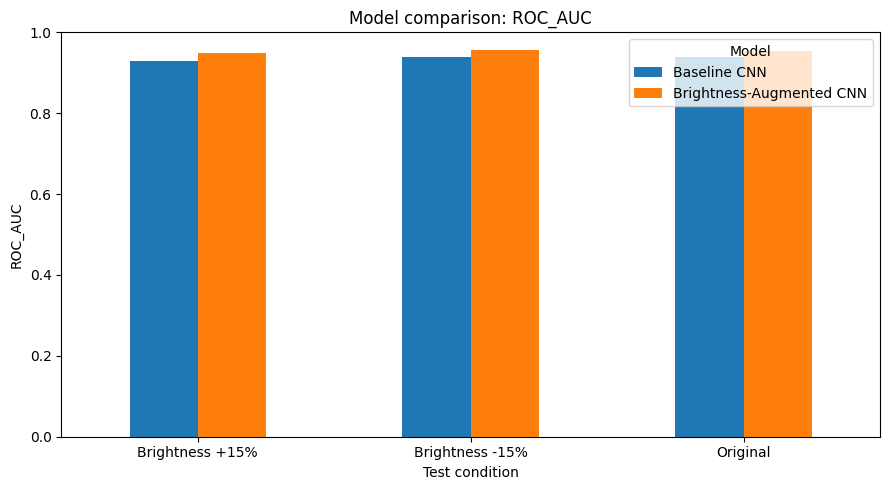

In [44]:
import matplotlib.pyplot as plt

for metric in ["accuracy", "roc_auc"]:
    pivot = final_comparison.pivot(
        index="condition",
        columns="model",
        values=metric
    )

    ax = pivot.plot(kind="bar", figsize=(9, 5))
    ax.set_title(f"Model comparison: {metric.upper()}")
    ax.set_ylabel(metric.upper())
    ax.set_xlabel("Test condition")
    ax.set_ylim(0, 1)
    plt.xticks(rotation=0)
    plt.legend(title="Model")
    plt.tight_layout()
    plt.show()

In [45]:
from pathlib import Path

OUTPUT_DIR = Path("/content/pneumonia_project")

for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print(f"{path.name:45s} {path.stat().st_size / (1024**2):8.2f} MB")

baseline_vs_brightness_augmentation.csv           0.00 MB
best_pneumonia_cnn.keras                         61.89 MB
brightness_robust_cnn.keras                      61.89 MB
brightness_robustness_results.csv                 0.00 MB
complete_robustness_report.csv                    0.00 MB


In [46]:
from google.colab import drive
from pathlib import Path
import shutil

drive.mount("/content/drive")

DRIVE_BACKUP = Path(
    "/content/drive/MyDrive/Pneumonia_Project_Backup"
)
DRIVE_BACKUP.mkdir(parents=True, exist_ok=True)

for filename in [
    "best_pneumonia_cnn.keras",
    "brightness_robust_cnn.keras",
    "pneumonia_cnn_final.keras",
    "evaluation_results.json",
    "test_predictions.csv",
    "brightness_robustness_results.csv",
    "baseline_vs_brightness_augmentation.csv",
    "complete_robustness_report.csv"
]:
    source = OUTPUT_DIR / filename

    if source.exists():
        shutil.copy2(source, DRIVE_BACKUP / filename)
        print("Backed up:", filename)
    else:
        print("Not found, skipped:", filename)

print("Backup folder:", DRIVE_BACKUP)

Mounted at /content/drive
Backed up: best_pneumonia_cnn.keras
Backed up: brightness_robust_cnn.keras
Not found, skipped: pneumonia_cnn_final.keras
Not found, skipped: evaluation_results.json
Not found, skipped: test_predictions.csv
Backed up: brightness_robustness_results.csv
Backed up: baseline_vs_brightness_augmentation.csv
Backed up: complete_robustness_report.csv
Backup folder: /content/drive/MyDrive/Pneumonia_Project_Backup


In [47]:
import shutil
from pathlib import Path

for location in ["/content", "/content/drive/MyDrive"]:
    total, used, free = shutil.disk_usage(location)

    print(f"\nLocation: {location}")
    print(f"Total: {total / (1024**3):.2f} GB")
    print(f"Used:  {used / (1024**3):.2f} GB")
    print(f"Free:  {free / (1024**3):.2f} GB")

print("\nExisting dataset folders:")
for path in [
    Path("/content/pneumonia_data"),
    Path("/content/drive/MyDrive/pneumonia_data"),
    Path("/content/drive/MyDrive/chest_xray")
]:
    print(path, "exists:", path.exists())


Location: /content
Total: 112.64 GB
Used:  47.44 GB
Free:  65.18 GB

Location: /content/drive/MyDrive
Total: 15.00 GB
Used:  0.35 GB
Free:  14.65 GB

Existing dataset folders:
/content/pneumonia_data exists: True
/content/drive/MyDrive/pneumonia_data exists: False
/content/drive/MyDrive/chest_xray exists: False


In [48]:
from pathlib import Path

root = Path("/content/pneumonia_data")

for path in root.iterdir():
    if path.is_dir():
        print("[DIR] ", path.name)
    elif path.is_file():
        print(
            "[FILE]", path.name,
            f"({path.stat().st_size / (1024**3):.2f} GB)"
        )

[FILE] chest-xray-pneumonia.zip (2.29 GB)
[DIR]  chest_xray


In [49]:
from pathlib import Path

search_roots = [
    Path("/content"),
    Path("/content/drive/MyDrive")
]

for root in search_roots:
    print(f"\nSearching {root}")

    for path in root.rglob("*rsna*"):
        if path.is_file():
            print(
                path,
                f"({path.stat().st_size / (1024**3):.2f} GB)"
            )


Searching /content

Searching /content/drive/MyDrive


In [50]:
from pathlib import Path

files_to_check = [
    "/content/pneumonia_project/best_pneumonia_cnn.keras",
    "/content/pneumonia_project/brightness_robust_cnn.keras",
    "/content/pneumonia_project/complete_robustness_report.csv",
    "/content/pneumonia_project/baseline_vs_brightness_augmentation.csv"
]

for filename in files_to_check:
    path = Path(filename)
    print(
        "FOUND" if path.exists() else "MISSING",
        filename
    )

FOUND /content/pneumonia_project/best_pneumonia_cnn.keras
FOUND /content/pneumonia_project/brightness_robust_cnn.keras
FOUND /content/pneumonia_project/complete_robustness_report.csv
FOUND /content/pneumonia_project/baseline_vs_brightness_augmentation.csv


In [51]:
from pathlib import Path
import shutil

source = Path("/content/pneumonia_project")
backup = Path("/content/drive/MyDrive/Pneumonia_Project_Backup")
backup.mkdir(parents=True, exist_ok=True)

files_to_copy = [
    "best_pneumonia_cnn.keras",
    "brightness_robust_cnn.keras",
    "complete_robustness_report.csv",
    "baseline_vs_brightness_augmentation.csv",
    "brightness_robustness_results.csv",
]

for name in files_to_copy:
    src = source / name
    if src.exists():
        dst = backup / name
        shutil.copy2(src, dst)
        print(f"BACKED UP: {name} ({dst.stat().st_size / (1024**2):.1f} MB)")
    else:
        print(f"NOT FOUND: {name}")

print("\nBackup folder:", backup)

BACKED UP: best_pneumonia_cnn.keras (61.9 MB)
BACKED UP: brightness_robust_cnn.keras (61.9 MB)
BACKED UP: complete_robustness_report.csv (0.0 MB)
BACKED UP: baseline_vs_brightness_augmentation.csv (0.0 MB)
BACKED UP: brightness_robustness_results.csv (0.0 MB)

Backup folder: /content/drive/MyDrive/Pneumonia_Project_Backup


In [52]:
from pathlib import Path

search_roots = [
    Path("/content"),
    Path("/content/drive/MyDrive")
]

keywords = ("nih", "chestxray14", "data_entry_2017",
            "test_labels.csv", "test_list.txt")

found = []

for root in search_roots:
    print(f"\nSearching: {root}")
    for pattern in ("*NIH*", "*nih*", "*ChestXray14*",
                    "*Data_Entry_2017*", "*test_labels.csv",
                    "*test_list.txt"):
        try:
            for path in root.rglob(pattern):
                if path.is_file():
                    found.append(path)
                    print(path)
        except (PermissionError, OSError):
            pass

if not found:
    print("No matching NIH metadata or files found.")


Searching: /content

Searching: /content/drive/MyDrive
No matching NIH metadata or files found.


In [54]:
import tensorflow as tf
from pathlib import Path

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

print("\nModel files:")
for name in [
    "best_pneumonia_cnn.keras",
    "brightness_robust_cnn.keras"
]:
    path = Path("/content/pneumonia_project") / name
    print(name, "EXISTS" if path.exists() else "MISSING")

print("\nDataset folders:")
for name in ["train", "test", "val"]:
    path = Path("/content/pneumonia_data/chest_xray") / name
    print(name, "EXISTS" if path.exists() else "MISSING")

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Model files:
best_pneumonia_cnn.keras EXISTS
brightness_robust_cnn.keras EXISTS

Dataset folders:
train EXISTS
test EXISTS
val EXISTS


In [55]:
from pathlib import Path

possible_paths = [
    Path("/content/Data_Entry_2017_v2020.csv"),
    Path("/content/drive/MyDrive/Data_Entry_2017_v2020.csv"),
    Path("/content/drive/MyDrive/Pneumonia_Project_Backup/Data_Entry_2017_v2020.csv"),
]

for path in possible_paths:
    if path.exists():
        print("FOUND:", path)
        print("Size:", round(path.stat().st_size / (1024**2), 2), "MB")
        break
else:
    print("CSV not found yet.")
    print("Upload Data_Entry_2017_v2020.csv to Colab or Google Drive.")

FOUND: /content/Data_Entry_2017_v2020.csv
Size: 8.59 MB


In [56]:
from pathlib import Path

search_roots = [
    Path("/content"),
    Path("/content/drive/MyDrive")
]

matches = []

for root in search_roots:
    for pattern in [
        "*Data_Entry_2017*.csv",
        "*ChestXray14*.csv",
        "*NIH*metadata*.csv"
    ]:
        try:
            matches.extend(root.rglob(pattern))
        except (PermissionError, OSError):
            pass

# Remove duplicate paths
matches = list(dict.fromkeys(matches))

if matches:
    print("NIH metadata files found:")
    for p in matches:
        print(f"{p} | {p.stat().st_size / (1024**2):.2f} MB")
else:
    print("NIH metadata CSV not found.")
    print("Download Data_Entry_2017_v2020.csv from the official NIH page:")
    print("https://nihcc.app.box.com/v/ChestXray-NIHCC")

NIH metadata files found:
/content/Data_Entry_2017_v2020.csv | 8.59 MB


In [57]:
import pandas as pd
from pathlib import Path

csv_path = None

for root in [
    Path("/content"),
    Path("/content/drive/MyDrive")
]:
    matches = list(root.rglob("Data_Entry_2017*.csv"))
    if matches:
        csv_path = matches[0]
        break

if csv_path is None:
    raise FileNotFoundError("NIH metadata CSV not found.")

nih_df = pd.read_csv(csv_path)

print("CSV:", csv_path)
print("Rows and columns:", nih_df.shape)
print("\nColumn names:")
print(nih_df.columns.tolist())

print("\nSample records:")
display(nih_df.head(5))

print("\nFinding-label distribution:")
print(nih_df["Finding Labels"].value_counts().head(20))

CSV: /content/Data_Entry_2017_v2020.csv
Rows and columns: (112120, 11)

Column names:
['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Sex', 'View Position', 'OriginalImage[Width', 'Height]', 'OriginalImagePixelSpacing[x', 'y]']

Sample records:


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Sex,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y]
0,00000001_000.png,Cardiomegaly,0,1,57,M,PA,2682,2749,0.143,0.143
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168
3,00000002_000.png,No Finding,0,2,80,M,PA,2500,2048,0.171,0.171
4,00000003_001.png,Hernia,0,3,74,F,PA,2500,2048,0.168,0.168



Finding-label distribution:
Finding Labels
No Finding                           60361
Infiltration                          9547
Atelectasis                           4215
Effusion                              3955
Nodule                                2705
Pneumothorax                          2194
Mass                                  2139
Effusion|Infiltration                 1603
Atelectasis|Infiltration              1350
Consolidation                         1310
Atelectasis|Effusion                  1165
Pleural_Thickening                    1126
Cardiomegaly                          1093
Emphysema                              892
Infiltration|Nodule                    829
Atelectasis|Effusion|Infiltration      737
Fibrosis                               727
Edema                                  628
Cardiomegaly|Effusion                  484
Consolidation|Infiltration             441
Name: count, dtype: int64


In [58]:
# Convert each finding string into a set of individual labels
nih_df["label_set"] = nih_df["Finding Labels"].fillna("").apply(
    lambda s: set(s.split("|"))
)

nih_positive = nih_df[
    nih_df["label_set"].apply(lambda labels: "Pneumonia" in labels)
].copy()

nih_negative = nih_df[
    nih_df["label_set"].apply(lambda labels: labels == {"No Finding"})
].copy()

print("Total metadata records:", len(nih_df))
print("Images labeled Pneumonia:", len(nih_positive))
print("Images labeled exactly No Finding:", len(nih_negative))

print("\nPatient counts:")
print("Positive patients:", nih_positive["Patient ID"].nunique())
print("Negative patients:", nih_negative["Patient ID"].nunique())

print("\nView positions:")
print(nih_df["View Position"].value_counts(dropna=False))

print("\nExample positive filenames:")
print(nih_positive["Image Index"].head().tolist())

print("\nExample negative filenames:")
print(nih_negative["Image Index"].head().tolist())

Total metadata records: 112120
Images labeled Pneumonia: 1431
Images labeled exactly No Finding: 60361

Patient counts:
Positive patients: 1008
Negative patients: 24907

View positions:
View Position
PA    67310
AP    44810
Name: count, dtype: int64

Example positive filenames:
['00000013_010.png', '00000032_012.png', '00000056_000.png', '00000061_012.png', '00000061_015.png']

Example negative filenames:
['00000002_000.png', '00000005_000.png', '00000005_001.png', '00000005_002.png', '00000005_003.png']


In [59]:
from pathlib import Path

image_roots = [
    Path("/content/images"),
    Path("/content/NIH"),
    Path("/content/nih"),
    Path("/content/drive/MyDrive/NIH"),
    Path("/content/drive/MyDrive/ChestXray14"),
]

for root in image_roots:
    if root.exists():
        image_count = sum(1 for _ in root.rglob("*.png"))
        print(f"FOUND: {root} | PNG images: {image_count}")
    else:
        print(f"Not present: {root}")

Not present: /content/images
Not present: /content/NIH
Not present: /content/nih
Not present: /content/drive/MyDrive/NIH
Not present: /content/drive/MyDrive/ChestXray14


In [60]:
!pip -q install datasets

In [61]:
from datasets import load_dataset

dataset_name = "timm/nih-chest-xray-14"

nih_stream = load_dataset(
    dataset_name,
    split="train",
    streaming=True
)

print("Dataset stream created.")

sample = next(iter(nih_stream))

print("\nAvailable fields:")
print(sample.keys())

print("\nImage field type:")
print(type(sample.get("image")))

print("\nImage identifier:")
print(sample.get("image_id"))

print("\nLabel names:")
print(sample.get("label_names"))

README.md:   0%|          | 0.00/7.54k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/32 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/32 [00:00<?, ?it/s]

Dataset stream created.

Available fields:
dict_keys(['image', 'labels', 'label_names', 'image_id', 'fold', 'patient_id', 'follow_up', 'patient_age', 'patient_sex', 'view_position', 'original_width', 'original_height', 'pixel_spacing_x', 'pixel_spacing_y', 'bboxes'])

Image field type:
<class 'PIL.JpegImagePlugin.JpegImageFile'>

Image identifier:
00000001_000

Label names:
['Cardiomegaly']


In [62]:
from collections import Counter
from itertools import islice

print("Dataset features:")
print(nih_stream.features)

print("\nInspecting 100 records...")
label_counts = Counter()
patient_ids = set()
image_sizes = Counter()
pneumonia_examples = []
normal_examples = []

for record in islice(iter(nih_stream), 100):
    labels = record.get("label_names") or []
    label_counts.update(labels)

    patient_ids.add(record.get("patient_id"))
    image_sizes.update([record["image"].size])

    if "Pneumonia" in labels and len(pneumonia_examples) < 3:
        pneumonia_examples.append(
            (record["image_id"], record["patient_id"], labels)
        )

    if "No Finding" in labels and len(normal_examples) < 3:
        normal_examples.append(
            (record["image_id"], record["patient_id"], labels)
        )

print("\nLabel counts in this sample:")
print(label_counts)

print("\nUnique patients:", len(patient_ids))
print("Image sizes:", image_sizes)
print("Pneumonia examples:", pneumonia_examples)
print("No Finding examples:", normal_examples)

Dataset features:
{'image': Image(mode=None, decode=True), 'labels': List(ClassLabel(names=['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Effusion', 'Emphysema', 'Fibrosis', 'Hernia', 'Infiltration', 'Mass', 'Nodule', 'Pleural_Thickening', 'Pneumonia', 'Pneumothorax'])), 'label_names': List(Value('string')), 'image_id': Value('string'), 'fold': Value('int8'), 'patient_id': Value('int32'), 'follow_up': Value('int32'), 'patient_age': Value('int32'), 'patient_sex': Value('string'), 'view_position': Value('string'), 'original_width': Value('int32'), 'original_height': Value('int32'), 'pixel_spacing_x': Value('float64'), 'pixel_spacing_y': Value('float64'), 'bboxes': List({'bbox': List(Value('float32'), length=4), 'label': ClassLabel(names=['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Effusion', 'Emphysema', 'Fibrosis', 'Hernia', 'Infiltration', 'Mass', 'Nodule', 'Pleural_Thickening', 'Pneumonia', 'Pneumothorax'])})}

Inspecting 100 records...

Label counts in this 

In [63]:
from itertools import islice
from collections import Counter

TARGET_PER_CLASS = 100
nih_selected = {"Pneumonia": [], "No Finding": []}
seen_patients = {"Pneumonia": set(), "No Finding": set()}
scanned = 0

# Re-create the stream iterator from the start
records = iter(nih_stream)

for record in records:
    scanned += 1
    labels = set(record.get("label_names") or [])
    patient = record.get("patient_id")

    # Exact pneumonia label, excluding other reported findings
    if labels == {"Pneumonia"}:
        category = "Pneumonia"
    elif not labels:
        # This mirror encodes findings as a list of positive labels.
        # An empty label list is not automatically equivalent to NIH "No Finding".
        category = None
    else:
        category = None

    if category and patient not in seen_patients[category]:
        nih_selected[category].append(record)
        seen_patients[category].add(patient)

    if all(len(nih_selected[c]) >= TARGET_PER_CLASS
           for c in nih_selected):
        break

    if scanned % 5000 == 0:
        print(
            f"Scanned {scanned:,} records | "
            f"Pneumonia: {len(nih_selected['Pneumonia'])} | "
            f"No Finding: {len(nih_selected['No Finding'])}"
        )

print("\nFinished scan.")
print("Records scanned:", scanned)
print("Pneumonia images selected:", len(nih_selected["Pneumonia"]))
print("No Finding images selected:", len(nih_selected["No Finding"]))

Scanned 5,000 records | Pneumonia: 16 | No Finding: 0
Scanned 10,000 records | Pneumonia: 30 | No Finding: 0
Scanned 15,000 records | Pneumonia: 38 | No Finding: 0
Scanned 20,000 records | Pneumonia: 51 | No Finding: 0
Scanned 25,000 records | Pneumonia: 59 | No Finding: 0
Scanned 30,000 records | Pneumonia: 69 | No Finding: 0
Scanned 35,000 records | Pneumonia: 82 | No Finding: 0
Scanned 40,000 records | Pneumonia: 92 | No Finding: 0
Scanned 45,000 records | Pneumonia: 105 | No Finding: 0
Scanned 50,000 records | Pneumonia: 120 | No Finding: 0
Scanned 55,000 records | Pneumonia: 139 | No Finding: 0
Scanned 60,000 records | Pneumonia: 148 | No Finding: 0
Scanned 65,000 records | Pneumonia: 163 | No Finding: 0
Scanned 70,000 records | Pneumonia: 176 | No Finding: 0
Scanned 75,000 records | Pneumonia: 182 | No Finding: 0
Scanned 80,000 records | Pneumonia: 200 | No Finding: 0
Scanned 85,000 records | Pneumonia: 215 | No Finding: 0

Finished scan.
Records scanned: 86524
Pneumonia images s

In [66]:
from itertools import islice

empty_label_records = 0
no_finding_records = 0
examples = []

for record in islice(iter(nih_stream), 5000):
    labels = record.get("label_names") or []

    if not labels:
        empty_label_records += 1
        if len(examples) < 5:
            examples.append((record["image_id"], labels))

    if "No Finding" in labels:
        no_finding_records += 1

print("Empty-label records in first 5,000:", empty_label_records)
print("Explicit No Finding records:", no_finding_records)
print("Empty-label examples:", examples)

Empty-label records in first 5,000: 3055
Explicit No Finding records: 0
Empty-label examples: [('00000002_000', []), ('00000005_000', []), ('00000005_001', []), ('00000005_002', []), ('00000005_003', [])]


In [67]:
import numpy as np
from PIL import Image
from itertools import islice

TARGET = 200

def preprocess_nih_image(record):
    img = record["image"].convert("L").resize((150, 150))
    arr = np.asarray(img, dtype=np.float32) / 255.0
    return arr[..., np.newaxis]

# Pass 1: collect pneumonia-positive images, one per patient
positive_images = []
positive_ids = []
positive_patients = set()

for record in iter(nih_stream):
    labels = set(record.get("label_names") or [])
    patient = record.get("patient_id")

    if "Pneumonia" not in labels:
        continue
    if patient in positive_patients:
        continue

    positive_images.append(preprocess_nih_image(record))
    positive_ids.append(record["image_id"])
    positive_patients.add(patient)

    if len(positive_images) >= TARGET:
        break

print("Positive images:", len(positive_images))
print("Unique positive patients:", len(positive_patients))

# Pass 2: collect images with no positive disease labels,
# excluding patients already selected for the positive class.
negative_images = []
negative_ids = []
negative_patients = set()

for record in iter(nih_stream):
    labels = set(record.get("label_names") or [])
    patient = record.get("patient_id")

    if labels:
        continue
    if patient in positive_patients or patient in negative_patients:
        continue

    negative_images.append(preprocess_nih_image(record))
    negative_ids.append(record["image_id"])
    negative_patients.add(patient)

    if len(negative_images) >= TARGET:
        break

print("Negative images:", len(negative_images))
print("Unique negative patients:", len(negative_patients))

if not positive_images or not negative_images:
    raise ValueError("Could not collect both classes. Do not evaluate yet.")

x_nih = np.stack(positive_images + negative_images)
y_nih = np.array(
    [1] * len(positive_images) + [0] * len(negative_images),
    dtype=np.int32
)

print("Evaluation array shape:", x_nih.shape)
print("Positive count:", int(y_nih.sum()))
print("Negative count:", int((y_nih == 0).sum()))

Positive images: 200
Unique positive patients: 200
Negative images: 200
Unique negative patients: 200
Evaluation array shape: (400, 150, 150, 1)
Positive count: 200
Negative count: 200


In [68]:
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)
import pandas as pd

project_dir = "/content/pneumonia_project"

baseline_model = tf.keras.models.load_model(
    f"{project_dir}/best_pneumonia_cnn.keras",
    compile=False
)

robust_model = tf.keras.models.load_model(
    f"{project_dir}/brightness_robust_cnn.keras",
    compile=False
)

def evaluate_model(name, model, x, y):
    probabilities = model.predict(x, verbose=0).reshape(-1)
    predictions = (probabilities >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y, predictions, labels=[0, 1]
    ).ravel()

    return {
        "Model": name,
        "Images": len(y),
        "Accuracy": accuracy_score(y, predictions),
        "Precision": precision_score(y, predictions, zero_division=0),
        "Sensitivity_Recall": recall_score(y, predictions, zero_division=0),
        "Specificity": tn / (tn + fp) if (tn + fp) else 0,
        "F1": f1_score(y, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y, probabilities),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    }

results = pd.DataFrame([
    evaluate_model("Baseline CNN", baseline_model, x_nih, y_nih),
    evaluate_model("Brightness-Augmented CNN", robust_model, x_nih, y_nih)
])

display(results.round(4))

results.to_csv(
    f"{project_dir}/nih_external_subset_results.csv",
    index=False
)

print("Saved results to nih_external_subset_results.csv")

,Model,Images,Accuracy,Precision,Sensitivity_Recall,Specificity,F1,ROC_AUC,TN,FP,FN,TP
0,Baseline CNN,400,0.5425,0.5244,0.915,0.17,0.6667,0.6108,34,166,17,183
1,Brightness-Augmented CNN,400,0.5450,0.5263,0.900,0.19,0.6642,0.6027,38,162,20,180


Saved results to nih_external_subset_results.csv


In [69]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

def inspect_scores(name, model, x, y):
    p = model.predict(x, verbose=0).reshape(-1)

    print(f"\n{name}")
    print("Probability range:", round(float(p.min()), 4), "to", round(float(p.max()), 4))
    print("Mean score for NIH positives:", round(float(p[y == 1].mean()), 4))
    print("Mean score for NIH negatives:", round(float(p[y == 0].mean()), 4))
    print("Median positive score:", round(float(np.median(p[y == 1])), 4))
    print("Median negative score:", round(float(np.median(p[y == 0])), 4))
    print("ROC-AUC:", round(float(roc_auc_score(y, p)), 4))

    rows = []
    for threshold in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
        pred = (p >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()

        rows.append({
            "Threshold": threshold,
            "Accuracy": accuracy_score(y, pred),
            "Precision": precision_score(y, pred, zero_division=0),
            "Sensitivity": recall_score(y, pred, zero_division=0),
            "Specificity": tn / (tn + fp),
            "F1": f1_score(y, pred, zero_division=0),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp
        })

    return pd.DataFrame(rows)

baseline_thresholds = inspect_scores(
    "Baseline CNN", baseline_model, x_nih, y_nih
)

robust_thresholds = inspect_scores(
    "Brightness-Augmented CNN", robust_model, x_nih, y_nih
)

print("\nBaseline threshold comparison:")
display(baseline_thresholds.round(3))

print("\nBrightness-augmented threshold comparison:")
display(robust_thresholds.round(3))


Baseline CNN
Probability range: 0.0017 to 1.0
Mean score for NIH positives: 0.9
Mean score for NIH negatives: 0.8285
Median positive score: 0.9999
Median negative score: 0.9977
ROC-AUC: 0.6108

Brightness-Augmented CNN
Probability range: 0.0013 to 1.0
Mean score for NIH positives: 0.8835
Mean score for NIH negatives: 0.8029
Median positive score: 0.9996
Median negative score: 0.9926
ROC-AUC: 0.6027

Baseline threshold comparison:


,Threshold,Accuracy,Precision,Sensitivity,Specificity,F1,TN,FP,FN,TP
0,0.1,0.522,0.512,0.975,0.070,0.671,14,186,5,195
1,0.2,0.525,0.513,0.960,0.090,0.669,18,182,8,192
2,0.3,0.540,0.522,0.955,0.125,0.675,25,175,9,191
3,0.4,0.540,0.522,0.930,0.150,0.669,30,170,14,186
4,0.5,0.542,0.524,0.915,0.170,0.667,34,166,17,183
5,0.6,0.550,0.529,0.905,0.195,0.668,39,161,19,181
6,0.7,0.535,0.521,0.865,0.205,0.650,41,159,27,173
7,0.8,0.530,0.519,0.830,0.230,0.638,46,154,34,166
8,0.9,0.532,0.521,0.800,0.265,0.631,53,147,40,160



Brightness-augmented threshold comparison:


,Threshold,Accuracy,Precision,Sensitivity,Specificity,F1,TN,FP,FN,TP
0,0.1,0.520,0.510,0.975,0.065,0.670,13,187,5,195
1,0.2,0.522,0.512,0.955,0.090,0.667,18,182,9,191
2,0.3,0.540,0.522,0.950,0.130,0.674,26,174,10,190
3,0.4,0.542,0.524,0.915,0.170,0.667,34,166,17,183
4,0.5,0.545,0.526,0.900,0.190,0.664,38,162,20,180
5,0.6,0.548,0.529,0.870,0.225,0.658,45,155,26,174
6,0.7,0.558,0.536,0.850,0.265,0.658,53,147,30,170
7,0.8,0.552,0.534,0.820,0.285,0.647,57,143,36,164
8,0.9,0.548,0.533,0.775,0.320,0.631,64,136,45,155


In [71]:
import numpy as np
from PIL import Image
from sklearn.metrics import accuracy_score, roc_auc_score

# We have the raw stream records of our 400 chosen images from the previous cell.
# Let's map over the positive and negative records we actually used to build x_nih.
def resize_nih_batch(interpolation):
    images = []
    # We stream the exact same 200 positive and 200 negative records to match y_nih's shape of 400
    records_to_process = []

    # Re-extract positive and negative records
    pos_count = 0
    for record in iter(nih_stream):
        labels = set(record.get("label_names") or [])
        patient = record.get("patient_id")
        if "Pneumonia" in labels and patient in positive_patients:
            records_to_process.append(record)
            pos_count += 1
            if pos_count >= 200:
                break

    neg_count = 0
    for record in iter(nih_stream):
        labels = set(record.get("label_names") or [])
        patient = record.get("patient_id")
        if not labels and patient in negative_patients:
            records_to_process.append(record)
            neg_count += 1
            if neg_count >= 200:
                break

    for record in records_to_process:
        img = record["image"].convert("L").resize(
            (150, 150), resample=interpolation
        )
        arr = np.asarray(img, dtype=np.float32) / 255.0
        images.append(arr[..., np.newaxis])
    return np.stack(images)

# Rebuild the same selected images with Keras-style nearest-neighbor resize
x_nih_nearest = resize_nih_batch(Image.Resampling.NEAREST)

# Compare predictions from the two resize approaches
for name, x in [
    ("Current preprocessing", x_nih),
    ("Nearest-neighbor resize", x_nih_nearest)
]:
    print(f"\n{name}")
    for model_name, model in [
        ("Baseline", baseline_model),
        ("Brightness-augmented", robust_model)
    ]:
        p = model.predict(x, verbose=0).reshape(-1)
        pred = (p >= 0.5).astype(int)
        print(
            model_name,
            "| Accuracy:", round(accuracy_score(y_nih, pred), 4),
            "| AUC:", round(roc_auc_score(y_nih, p), 4),
            "| Mean positive score:", round(float(p[y_nih == 1].mean()), 4),
            "| Mean negative score:", round(float(p[y_nih == 0].mean()), 4)
        )

# Inspect original test-set scores as a reference
print("\nOriginal test-set reference")
for model_name, model in [
    ("Baseline", baseline_model),
    ("Brightness-augmented", robust_model)
]:
    p = model.predict(x_test, verbose=0).reshape(-1)
    print(
        model_name,
        "| AUC:", round(roc_auc_score(y_test, p), 4),
        "| Mean score:", round(float(p.mean()), 4),
        "| Score percentiles:", np.round(
            np.percentile(p, [0, 25, 50, 75, 100]), 4
        )
    )


ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_1555/3801471000.py", line 42, in <cell line: 0>
    x_nih_nearest = resize_nih_batch(Image.Resampling.NEAREST)
  File "/tmp/ipykernel_1555/3801471000.py", line 14, in resize_nih_batch
    for record in iter(nih_stream):
                  ~~~~^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/datasets/iterable_dataset.py", line 2690, in __iter__
    for key, example in ex_iterable:
                        ^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/datasets/iterable_dataset.py", line 2228, in __iter__
    batch = formatter.format_batch(pa_table)
  File "/usr/local/lib/python3.13/dist-packages/datasets/formatting/formatting.py", line 472, in format_batch
    batch = self.python_features_decoder.

TypeError: object of type 'NoneType' has no len()

In [72]:
import numpy as np
from PIL import Image
from sklearn.metrics import accuracy_score, roc_auc_score

def resize_nih_batch(interpolation):
    images = []
    for record in nih_selected["Pneumonia"] + nih_selected["No Finding"]:
        img = record["image"].convert("L").resize(
            (150, 150), resample=interpolation
        )
        arr = np.asarray(img, dtype=np.float32) / 255.0
        images.append(arr[..., np.newaxis])
    return np.stack(images)

# Rebuild the same selected images with Keras-style nearest-neighbor resize
x_nih_nearest = resize_nih_batch(Image.Resampling.NEAREST)

# Compare predictions from the two resize approaches
for name, x in [
    ("Current preprocessing", x_nih),
    ("Nearest-neighbor resize", x_nih_nearest)
]:
    print(f"\n{name}")
    for model_name, model in [
        ("Baseline", baseline_model),
        ("Brightness-augmented", robust_model)
    ]:
        p = model.predict(x, verbose=0).reshape(-1)
        pred = (p >= 0.5).astype(int)
        print(
            model_name,
            "| Accuracy:", round(accuracy_score(y_nih, pred), 4),
            "| AUC:", round(roc_auc_score(y_nih, p), 4),
            "| Mean positive score:", round(float(p[y_nih == 1].mean()), 4),
            "| Mean negative score:", round(float(p[y_nih == 0].mean()), 4)
        )

# Inspect original test-set scores as a reference
print("\nOriginal test-set reference")
for model_name, model in [
    ("Baseline", baseline_model),
    ("Brightness-augmented", robust_model)
]:
    p = model.predict(x_test, verbose=0).reshape(-1)
    print(
        model_name,
        "| AUC:", round(roc_auc_score(y_test, p), 4),
        "| Mean score:", round(float(p.mean()), 4),
        "| Score percentiles:", np.round(
            np.percentile(p, [0, 25, 50, 75, 100]), 4
        )
    )


Current preprocessing
Baseline | Accuracy: 0.5425 | AUC: 0.6108 | Mean positive score: 0.9 | Mean negative score: 0.8285
Brightness-augmented | Accuracy: 0.545 | AUC: 0.6027 | Mean positive score: 0.8835 | Mean negative score: 0.8029

Nearest-neighbor resize


ValueError: Found input variables with inconsistent numbers of samples: [400, 217]

In [ ]:
import numpy as np
from PIL import Image
from sklearn.metrics import accuracy_score, roc_auc_score

# To match the exact order of x_nih (first 200 positive, then 200 negative)
# we can stream the dataset again and collect the PIL images matching our patient sets.
pos_images = []
neg_images = []

for record in iter(nih_stream):
    labels = set(record.get("label_names") or [])
    patient = record.get("patient_id")

    # Collect corresponding positive records
    if "Pneumonia" in labels and patient in positive_patients:
        if len(pos_images) < 200:
            pos_images.append(record["image"])

    # Collect corresponding negative records
    if not labels and patient in negative_patients:
        if len(neg_images) < 200:
            neg_images.append(record["image"])

    if len(pos_images) == 200 and len(neg_images) == 200:
        break

selected_images = pos_images + neg_images

print("Selected records:", len(selected_images))
print("Labels:", len(y_nih))

if len(selected_images) != len(y_nih):
    raise ValueError(
        f"Could only reconstruct {len(selected_images)} images, "
        f"which does not match y_nih length of {len(y_nih)}."
    )

def resize_batch(pil_images, resample):
    images = []
    for img in pil_images:
        resized_img = img.convert("L").resize(
            (150, 150), resample=resample
        )
        images.append(
            np.asarray(resized_img, dtype=np.float32)[..., None] / 255.0
        )
    return np.stack(images)

x_nih_nearest = resize_batch(
    selected_images, Image.Resampling.NEAREST
)

print("Current preprocessing shape:", x_nih.shape)
print("Nearest-neighbor shape:", x_nih_nearest.shape)

for name, x in [
    ("Current preprocessing", x_nih),
    ("Nearest-neighbor resize", x_nih_nearest)
]:
    print(f"\n{name}")
    for model_name, model in [
        ("Baseline", baseline_model),
        ("Brightness-augmented", robust_model)
    ]:
        p = model.predict(x, verbose=0).reshape(-1)
        pred = (p >= 0.5).astype(int)

        print(
            f"{model_name}: "
            f"Accuracy={accuracy_score(y_nih, pred):.4f}, "
            f"AUC={roc_auc_score(y_nih, p):.4f}"
        )

In [74]:
print("x_nih shape:", x_nih.shape)
print("y_nih shape:", y_nih.shape)
print("Class counts:", {
    "negative": int((y_nih == 0).sum()),
    "positive": int((y_nih == 1).sum())
})

print("\nImage value range:")
print("Min:", float(x_nih.min()))
print("Max:", float(x_nih.max()))
print("Mean:", float(x_nih.mean()))
print("Standard deviation:", float(x_nih.std()))

x_nih shape: (400, 150, 150, 1)
y_nih shape: (400,)
Class counts: {'negative': 200, 'positive': 200}

Image value range:
Min: 0.0
Max: 1.0
Mean: 0.5489257574081421
Standard deviation: 0.24836866557598114


In [75]:
from sklearn.metrics import roc_auc_score, accuracy_score
import numpy as np

for name, model in [
    ("Baseline CNN", baseline_model),
    ("Brightness-augmented CNN", robust_model)
]:
    p = model.predict(x_nih, verbose=0).reshape(-1)

    print(f"\n{name}")
    print("AUC:", round(roc_auc_score(y_nih, p), 4))
    print("Accuracy at 0.5:", round(
        accuracy_score(y_nih, (p >= 0.5).astype(int)), 4
    ))
    print("Mean probability:", round(float(p.mean()), 4))
    print("Probability percentiles:", np.round(
        np.percentile(p, [0, 25, 50, 75, 100]), 4
    ))


Baseline CNN
AUC: 0.6108
Accuracy at 0.5: 0.5425
Mean probability: 0.8642
Probability percentiles: [0.0017 0.9299 0.9995 1.     1.    ]

Brightness-augmented CNN
AUC: 0.6027
Accuracy at 0.5: 0.545
Mean probability: 0.8432
Probability percentiles: [0.0013 0.8376 0.9983 1.     1.    ]


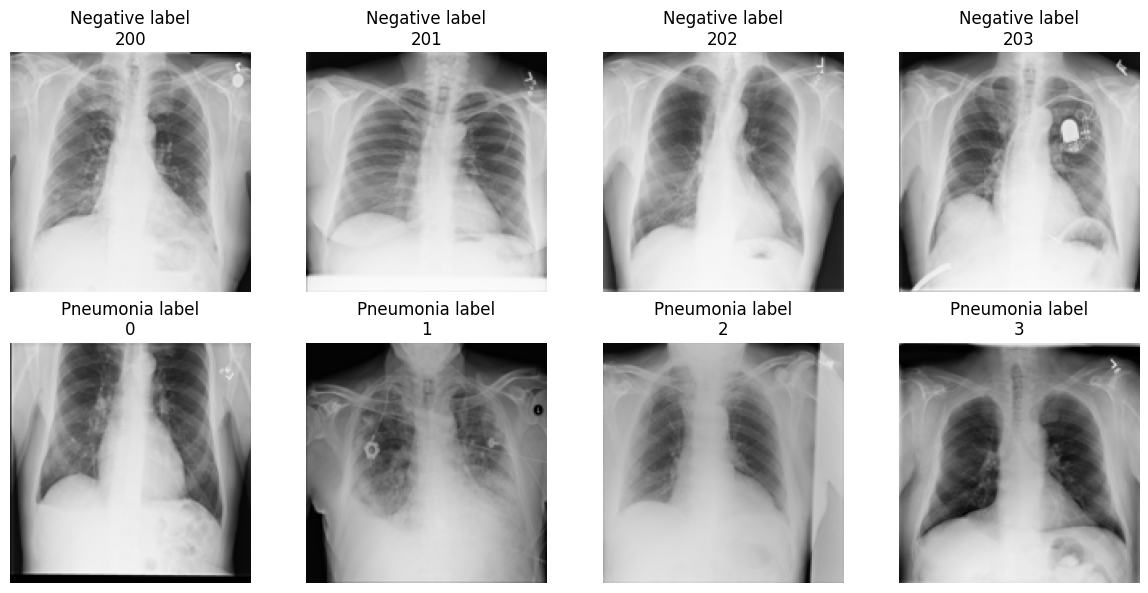

In [76]:
import numpy as np
import matplotlib.pyplot as plt

# Inspect representative images from both classes
negative_idx = np.where(y_nih == 0)[0][:4]
positive_idx = np.where(y_nih == 1)[0][:4]

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for col, idx in enumerate(negative_idx):
    axes[0, col].imshow(x_nih[idx].squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[0, col].set_title(f"Negative label\n{idx}")
    axes[0, col].axis("off")

for col, idx in enumerate(positive_idx):
    axes[1, col].imshow(x_nih[idx].squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[1, col].set_title(f"Pneumonia label\n{idx}")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()

In [77]:
print("Training pipeline: grayscale, 150x150")
print("NIH evaluation shape:", x_nih.shape)

print("\nPer-class image statistics")
for label, name in [(0, "Negative label"), (1, "Pneumonia label")]:
    subset = x_nih[y_nih == label]
    print(
        name,
        "| mean:", round(float(subset.mean()), 4),
        "| std:", round(float(subset.std()), 4),
        "| min:", round(float(subset.min()), 4),
        "| max:", round(float(subset.max()), 4)
    )

Training pipeline: grayscale, 150x150
NIH evaluation shape: (400, 150, 150, 1)

Per-class image statistics
Negative label | mean: 0.5484 | std: 0.2523 | min: 0.0 | max: 1.0
Pneumonia label | mean: 0.5494 | std: 0.2443 | min: 0.0 | max: 1.0


In [78]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, roc_auc_score

models = {
    "Baseline CNN": baseline_model,
    "Brightness-augmented CNN": robust_model
}

rows = []

for name, model in models.items():
    probabilities = model.predict(x_nih, verbose=0).reshape(-1)
    predictions = (probabilities >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_nih, predictions, labels=[0, 1]
    ).ravel()

    rows.append({
        "Model": name,
        "Predicted pneumonia": int(predictions.sum()),
        "Predicted negative": int((predictions == 0).sum()),
        "False positives": int(fp),
        "False negatives": int(fn),
        "Specificity": round(tn / (tn + fp), 4),
        "Sensitivity": round(tp / (tp + fn), 4),
        "ROC-AUC": round(roc_auc_score(y_nih, probabilities), 4)
    })

display(pd.DataFrame(rows))

,Model,Predicted pneumonia,Predicted negative,False positives,False negatives,Specificity,Sensitivity,ROC-AUC
0,Baseline CNN,349,51,166,17,0.17,0.915,0.6108
1,Brightness-augmented CNN,342,58,162,20,0.19,0.900,0.6027


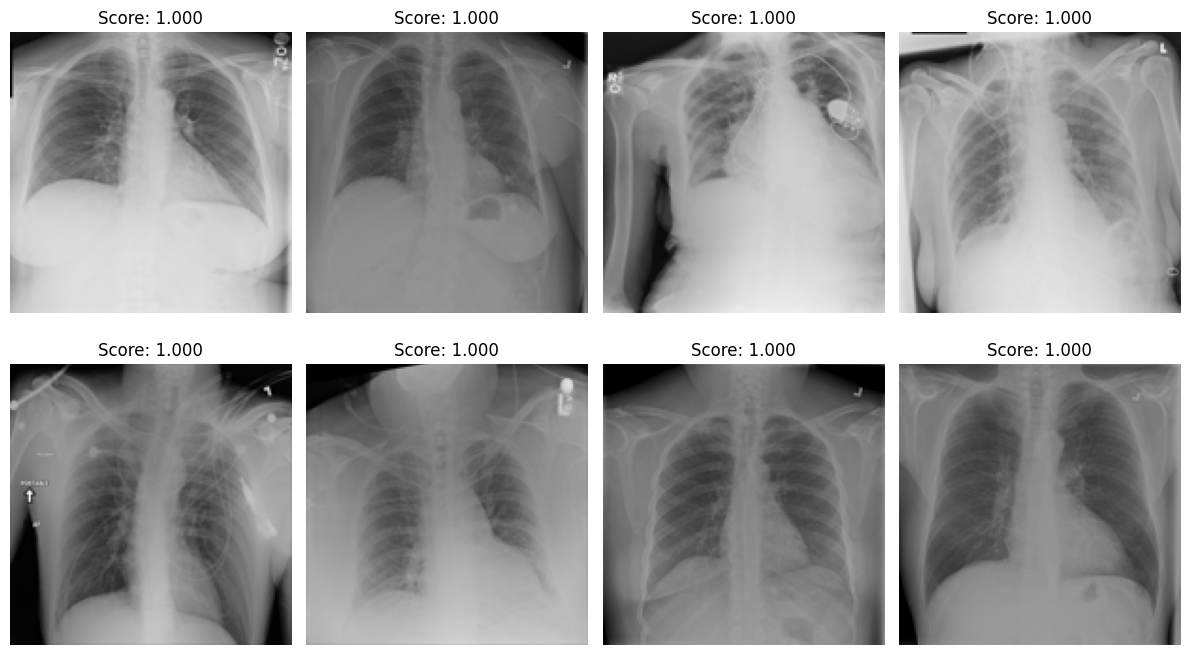

In [79]:
import matplotlib.pyplot as plt
import numpy as np

p = baseline_model.predict(x_nih, verbose=0).reshape(-1)
negative_indices = np.where(y_nih == 0)[0]
top_indices = negative_indices[
    np.argsort(p[negative_indices])[-8:][::-1]
]

fig, axes = plt.subplots(2, 4, figsize=(12, 7))

for ax, idx in zip(axes.flat, top_indices):
    ax.imshow(x_nih[idx].squeeze(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Score: {p[idx]:.3f}")
    ax.axis("off")

plt.tight_layout()
plt.show()

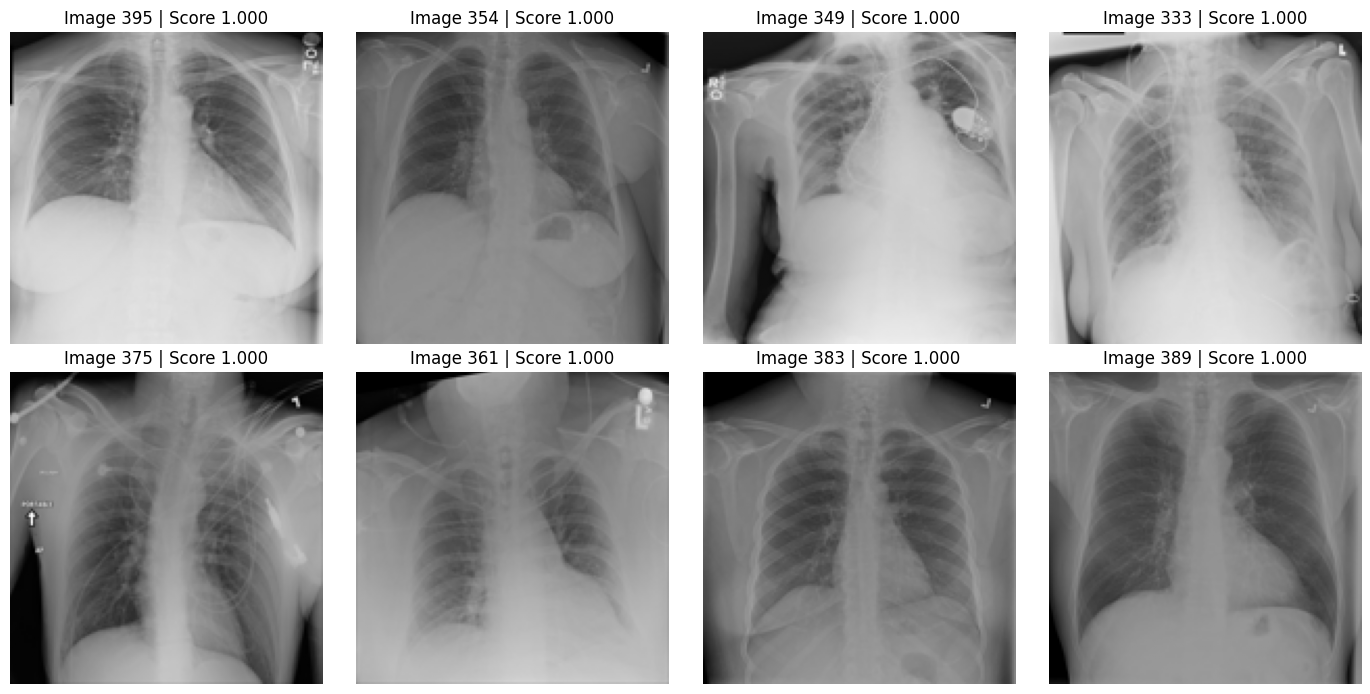

In [80]:
import numpy as np
import matplotlib.pyplot as plt

probabilities = baseline_model.predict(
    x_nih, verbose=0
).reshape(-1)

negative_indices = np.where(y_nih == 0)[0]
top_indices = negative_indices[
    np.argsort(probabilities[negative_indices])[-8:][::-1]
]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for ax, idx in zip(axes.flat, top_indices):
    ax.imshow(x_nih[idx].squeeze(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Image {idx} | Score {probabilities[idx]:.3f}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [81]:
for label, name in [(0, "Negative labels"), (1, "Pneumonia labels")]:
    scores = probabilities[y_nih == label]

    print(f"\n{name}")
    print("25th percentile:", round(float(np.percentile(scores, 25)), 4))
    print("Median:", round(float(np.median(scores)), 4))
    print("75th percentile:", round(float(np.percentile(scores, 75)), 4))


Negative labels
25th percentile: 0.8343
Median: 0.9977
75th percentile: 1.0

Pneumonia labels
25th percentile: 0.9829
Median: 0.9999
75th percentile: 1.0


In [82]:
print("Model input shape:", baseline_model.input_shape)
print("Model output shape:", baseline_model.output_shape)

print("\nFinal model layers:")
for layer in baseline_model.layers[-6:]:
    print(
        layer.name,
        "|", layer.__class__.__name__,
        "| activation:", getattr(layer, "activation", None)
    )

print("\nTraining dataset folders:")
import os

train_dir = "/content/pneumonia_data/chest_xray/train"

for folder in sorted(os.listdir(train_dir)):
    path = os.path.join(train_dir, folder)
    if os.path.isdir(path):
        print(folder, ":", len(os.listdir(path)), "files")

Model input shape: (None, 150, 150, 1)
Model output shape: (None, 1)

Final model layers:
max_pooling2d_4 | MaxPooling2D | activation: None
dropout_5 | Dropout | activation: None
flatten_1 | Flatten | activation: None
dense_2 | Dense | activation: <function relu at 0x7cecb5a818a0>
dropout_6 | Dropout | activation: None
dense_3 | Dense | activation: <function sigmoid at 0x7cecb59a3600>

Training dataset folders:
NORMAL : 1341 files
PNEUMONIA : 3875 files


In [83]:
test_dir = "/content/pneumonia_data/chest_xray/test"

from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np

test_gen = ImageDataGenerator(rescale=1./255).flow_from_directory(
    test_dir,
    target_size=(150, 150),
    color_mode="grayscale",
    class_mode="binary",
    batch_size=32,
    shuffle=False
)

test_x, test_y = next(iter(test_gen))
print("Class mapping:", test_gen.class_indices)
print("Test batch shape:", test_x.shape)

p = baseline_model.predict(test_x, verbose=0).reshape(-1)
print("First 10 probabilities:", np.round(p[:10], 4))
print("Probability percentiles:", np.round(
    np.percentile(p, [0, 25, 50, 75, 100]), 4
))

Found 624 images belonging to 2 classes.
Class mapping: {'NORMAL': 0, 'PNEUMONIA': 1}
Test batch shape: (32, 150, 150, 1)
First 10 probabilities: [0.005  0.0577 0.1755 0.2918 0.0371 0.005  0.0042 0.0145 0.0191 0.1231]
Probability percentiles: [1.000e-04 1.690e-02 3.740e-02 1.405e-01 9.997e-01]


In [84]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    confusion_matrix
)

# Predict on the complete original test set
test_gen.reset()
test_prob = baseline_model.predict(
    test_gen, verbose=1
).reshape(-1)

test_y = test_gen.classes
nih_prob = baseline_model.predict(
    x_nih, verbose=1
).reshape(-1)

def summarize_scores(name, y, p):
    pred = (p >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y, pred, labels=[0, 1]
    ).ravel()

    return {
        "Dataset": name,
        "Images": len(y),
        "Accuracy": round(accuracy_score(y, pred), 4),
        "ROC-AUC": round(roc_auc_score(y, p), 4),
        "Mean score": round(float(p.mean()), 4),
        "Median score": round(float(np.median(p)), 4),
        "Specificity": round(tn / (tn + fp), 4),
        "Sensitivity": round(tp / (tp + fn), 4)
    }

results = pd.DataFrame([
    summarize_scores("Original test set", test_y, test_prob),
    summarize_scores("NIH selected subset", y_nih, nih_prob)
])

display(results)

20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 156ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


,Dataset,Images,Accuracy,ROC-AUC,Mean score,Median score,Specificity,Sensitivity
0,Original test set,624,0.8766,0.9391,0.6516,0.9872,0.8162,0.9128
1,NIH selected subset,400,0.5425,0.6108,0.8642,0.9995,0.1700,0.9150


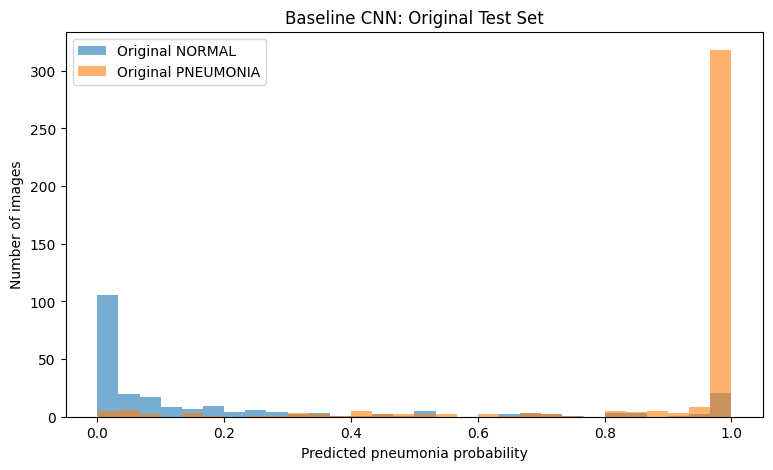

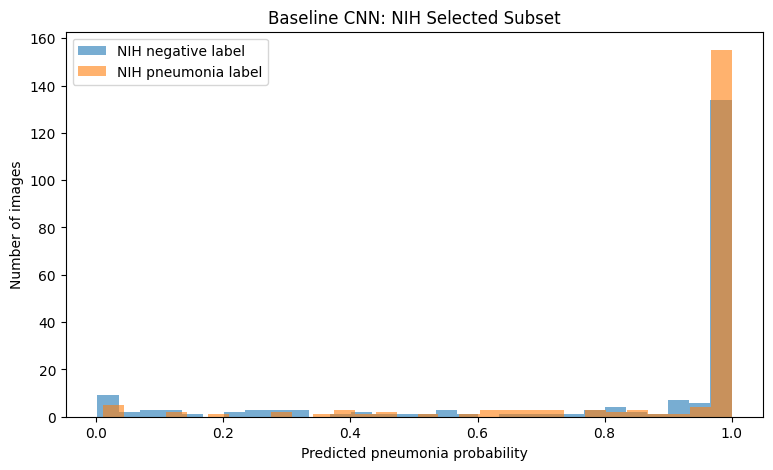

In [85]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    test_prob[test_y == 0],
    bins=30, alpha=0.6, label="Original NORMAL"
)
plt.hist(
    test_prob[test_y == 1],
    bins=30, alpha=0.6, label="Original PNEUMONIA"
)

plt.xlabel("Predicted pneumonia probability")
plt.ylabel("Number of images")
plt.title("Baseline CNN: Original Test Set")
plt.legend()
plt.show()

plt.figure(figsize=(9, 5))

plt.hist(
    nih_prob[y_nih == 0],
    bins=30, alpha=0.6, label="NIH negative label"
)
plt.hist(
    nih_prob[y_nih == 1],
    bins=30, alpha=0.6, label="NIH pneumonia label"
)

plt.xlabel("Predicted pneumonia probability")
plt.ylabel("Number of images")
plt.title("Baseline CNN: NIH Selected Subset")
plt.legend()
plt.show()

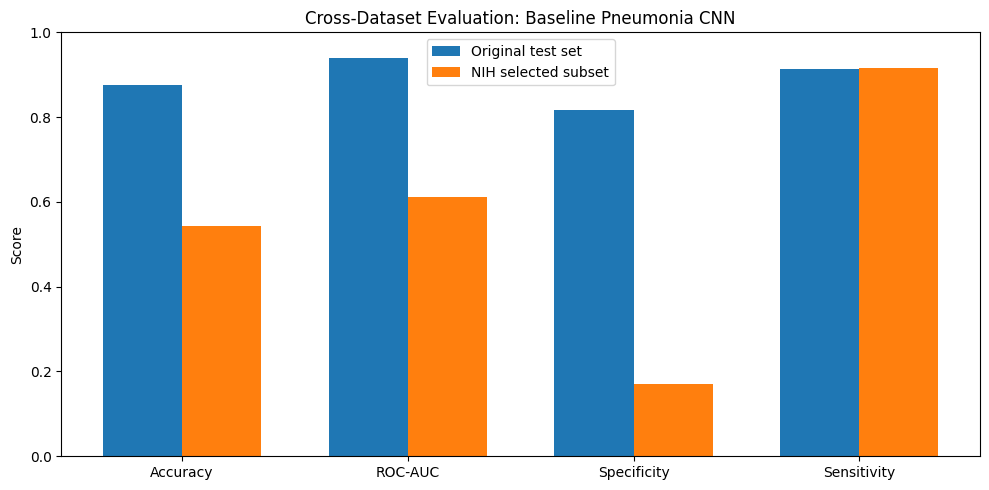

In [86]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "ROC-AUC", "Specificity", "Sensitivity"]

original = [0.8766, 0.9391, 0.8162, 0.9128]
nih = [0.5425, 0.6108, 0.1700, 0.9150]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x - width / 2, original, width, label="Original test set")
plt.bar(x + width / 2, nih, width, label="NIH selected subset")

plt.xticks(x, metrics)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Cross-Dataset Evaluation: Baseline Pneumonia CNN")
plt.legend()
plt.tight_layout()
plt.show()

In [87]:
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

assert x_nih.shape[0] == len(y_nih), "NIH images and labels mismatch"
assert x_nih.shape[1:] == (150, 150, 1), "Unexpected image shape"
assert set(np.unique(y_nih)).issubset({0, 1}), "Unexpected labels"

print("TensorFlow:", tf.__version__)
print("NIH images:", len(y_nih))
print("Image shape:", x_nih.shape)
print("Label counts:", dict(zip(
    *np.unique(y_nih, return_counts=True)
)))
print("Input range:", float(x_nih.min()), float(x_nih.max()))
print("Baseline output:", baseline_model.output_shape)
print("Augmented output:", robust_model.output_shape)

TensorFlow: 2.21.0
NIH images: 400
Image shape: (400, 150, 150, 1)
Label counts: {np.int32(0): np.int64(200), np.int32(1): np.int64(200)}
Input range: 0.0 1.0
Baseline output: (None, 1)
Augmented output: (None, 1)


In [88]:
# Predict on all 624 original test images
test_gen.reset()
test_prob = baseline_model.predict(test_gen, verbose=0).reshape(-1)
test_y = test_gen.classes.copy()

# Predict on the same 400 NIH images for both models
nih_baseline_prob = baseline_model.predict(
    x_nih, verbose=0
).reshape(-1)

nih_robust_prob = robust_model.predict(
    x_nih, verbose=0
).reshape(-1)

def calculate_metrics(name, y, p, threshold=0.5):
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y, pred, labels=[0, 1]
    ).ravel()

    return {
        "Dataset/Model": name,
        "N": len(y),
        "Accuracy": accuracy_score(y, pred),
        "ROC-AUC": roc_auc_score(y, p),
        "Sensitivity": tp / (tp + fn) if tp + fn else 0,
        "Specificity": tn / (tn + fp) if tn + fp else 0,
        "Precision": tp / (tp + fp) if tp + fp else 0,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    }

results = pd.DataFrame([
    calculate_metrics("Original test / Baseline", test_y, test_prob),
    calculate_metrics("NIH subset / Baseline", y_nih, nih_baseline_prob),
    calculate_metrics("NIH subset / Brightness-augmented", y_nih, nih_robust_prob)
])

display(results.round(4))

,Dataset/Model,N,Accuracy,ROC-AUC,Sensitivity,Specificity,Precision,TN,FP,FN,TP
0,Original test / Baseline,624,0.8766,0.9391,0.9128,0.8162,0.8922,191,43,34,356
1,NIH subset / Baseline,400,0.5425,0.6108,0.9150,0.1700,0.5244,34,166,17,183
2,NIH subset / Brightness-augmented,400,0.5450,0.6027,0.9000,0.1900,0.5263,38,162,20,180


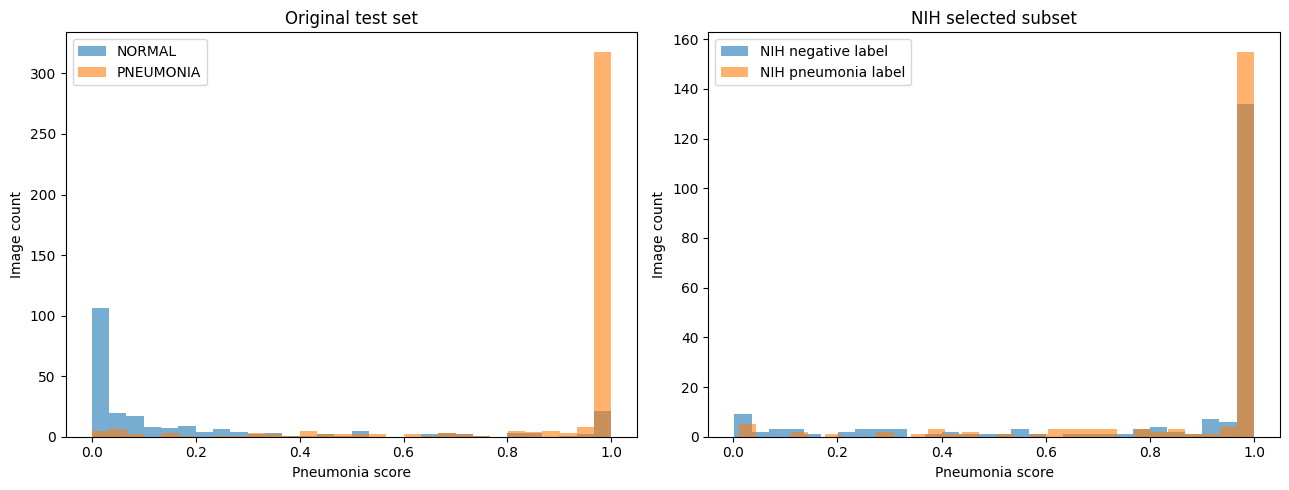

In [89]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(
    test_prob[test_y == 0], bins=30, alpha=0.6,
    label="NORMAL"
)
axes[0].hist(
    test_prob[test_y == 1], bins=30, alpha=0.6,
    label="PNEUMONIA"
)
axes[0].set_title("Original test set")
axes[0].set_xlabel("Pneumonia score")
axes[0].set_ylabel("Image count")
axes[0].legend()

axes[1].hist(
    nih_baseline_prob[y_nih == 0], bins=30, alpha=0.6,
    label="NIH negative label"
)
axes[1].hist(
    nih_baseline_prob[y_nih == 1], bins=30, alpha=0.6,
    label="NIH pneumonia label"
)
axes[1].set_title("NIH selected subset")
axes[1].set_xlabel("Pneumonia score")
axes[1].set_ylabel("Image count")
axes[1].legend()

plt.tight_layout()
plt.show()

In [90]:
import os

output_dir = "/content/pneumonia_project"
os.makedirs(output_dir, exist_ok=True)

results.to_csv(
    os.path.join(output_dir, "cross_dataset_baseline_results.csv"),
    index=False
)

results.to_csv(
    "/content/drive/MyDrive/Pneumonia_Project_Backup/"
    "cross_dataset_baseline_results.csv",
    index=False
)

print("Results saved locally and to Google Drive.")

Results saved locally and to Google Drive.


In [91]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt

def percentile_contrast_stretch(images, low=1, high=99):
    """Stretch each image's intensity percentiles to [0, 1]."""
    output = np.empty_like(images, dtype=np.float32)

    for i, image in enumerate(images):
        img = image.squeeze().astype(np.float32)
        lo, hi = np.percentile(img, [low, high])

        if hi > lo:
            img = (img - lo) / (hi - lo)
        else:
            img = np.zeros_like(img)

        output[i, :, :, 0] = np.clip(img, 0, 1)

    return output


x_nih_contrast = percentile_contrast_stretch(x_nih)

print("Original:", x_nih.shape)
print("Contrast-stretched:", x_nih_contrast.shape)
print("Original range:", float(x_nih.min()), float(x_nih.max()))
print(
    "Contrast-stretched range:",
    float(x_nih_contrast.min()),
    float(x_nih_contrast.max())
)

Original: (400, 150, 150, 1)
Contrast-stretched: (400, 150, 150, 1)
Original range: 0.0 1.0
Contrast-stretched range: 0.0 1.0


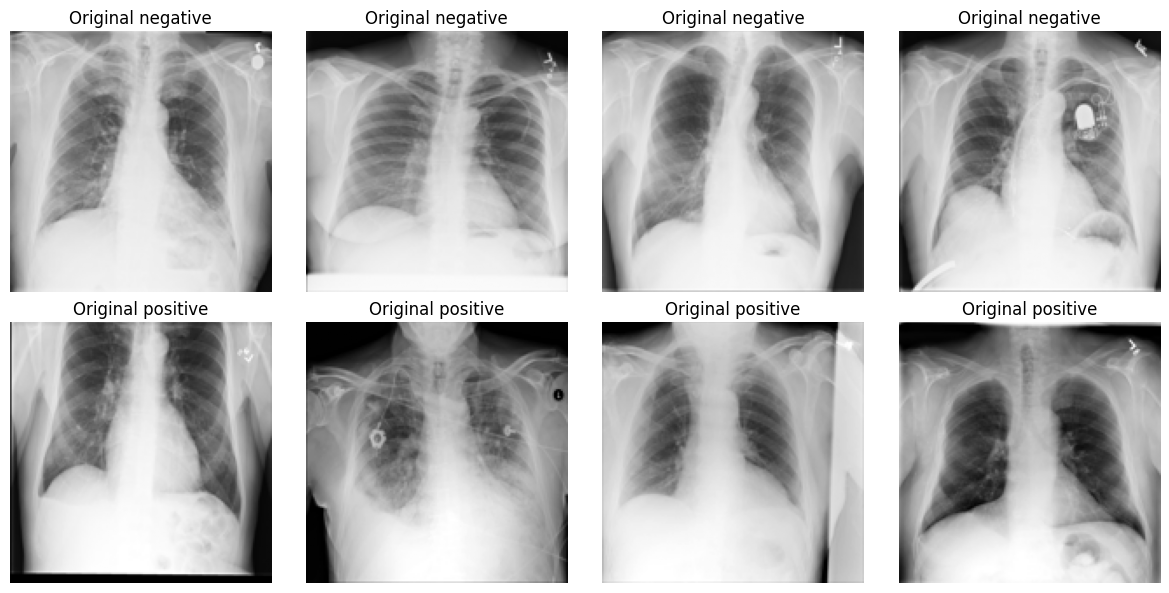

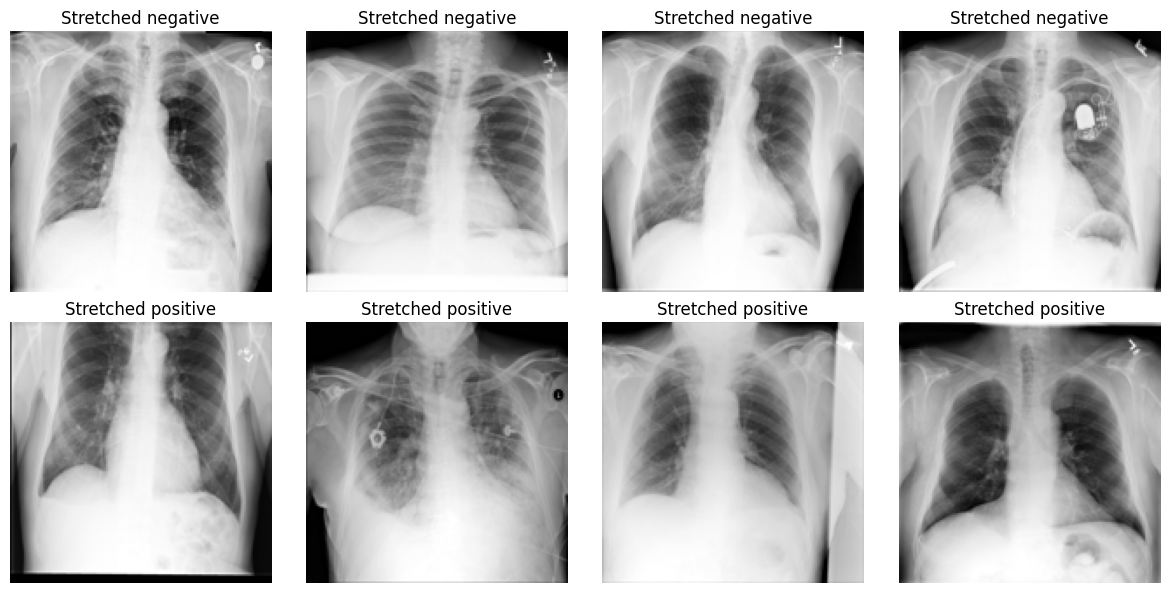

In [92]:
# Display four images from each label group
indices = list(np.where(y_nih == 0)[0][:4])
indices += list(np.where(y_nih == 1)[0][:4])

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for col, idx in enumerate(indices[:4]):
    axes[0, col].imshow(
        x_nih[idx].squeeze(), cmap="gray", vmin=0, vmax=1
    )
    axes[0, col].set_title("Original negative")

for col, idx in enumerate(indices[4:]):
    axes[1, col].imshow(
        x_nih_contrast[idx].squeeze(), cmap="gray", vmin=0, vmax=1
    )
    axes[1, col].set_title("Original positive")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for col, idx in enumerate(indices[:4]):
    axes[0, col].imshow(
        x_nih_contrast[idx].squeeze(),
        cmap="gray", vmin=0, vmax=1
    )
    axes[0, col].set_title("Stretched negative")

for col, idx in enumerate(indices[4:]):
    axes[1, col].imshow(
        x_nih_contrast[idx].squeeze(),
        cmap="gray", vmin=0, vmax=1
    )
    axes[1, col].set_title("Stretched positive")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [93]:
from sklearn.metrics import (
    accuracy_score, roc_auc_score, confusion_matrix
)

def evaluate_model(model, images, labels, model_name, preprocessing):
    scores = model.predict(images, verbose=0).reshape(-1)
    predictions = (scores >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        labels, predictions, labels=[0, 1]
    ).ravel()

    return {
        "Preprocessing": preprocessing,
        "Model": model_name,
        "Accuracy": accuracy_score(labels, predictions),
        "ROC-AUC": roc_auc_score(labels, scores),
        "Sensitivity": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "Precision": tp / (tp + fp) if tp + fp else 0,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    }


model_list = [
    ("Baseline CNN", baseline_model),
    ("Brightness-augmented CNN", robust_model)
]

input_variants = [
    ("Original inputs", x_nih),
    ("Percentile contrast stretch", x_nih_contrast)
]

experiment_rows = []

for preprocessing_name, images in input_variants:
    for model_name, model in model_list:
        row = evaluate_model(
            model,
            images,
            y_nih,
            model_name,
            preprocessing_name
        )
        experiment_rows.append(row)

experiment_results = pd.DataFrame(experiment_rows)

display(
    experiment_results
    .sort_values(["Model", "Preprocessing"])
    .round(4)
)

,Preprocessing,Model,Accuracy,ROC-AUC,Sensitivity,Specificity,Precision,TN,FP,FN,TP
0,Original inputs,Baseline CNN,0.5425,0.6108,0.915,0.17,0.5244,34,166,17,183
2,Percentile contrast stretch,Baseline CNN,0.5050,0.5961,0.720,0.29,0.5035,58,142,56,144
1,Original inputs,Brightness-augmented CNN,0.5450,0.6027,0.900,0.19,0.5263,38,162,20,180
3,Percentile contrast stretch,Brightness-augmented CNN,0.5475,0.5950,0.775,0.32,0.5326,64,136,45,155


In [94]:
output_dir = "/content/pneumonia_project"
backup_dir = "/content/drive/MyDrive/Pneumonia_Project_Backup"

os.makedirs(output_dir, exist_ok=True)
os.makedirs(backup_dir, exist_ok=True)

experiment_results.to_csv(
    os.path.join(output_dir, "nih_preprocessing_experiment.csv"),
    index=False
)

experiment_results.to_csv(
    os.path.join(backup_dir, "nih_preprocessing_experiment.csv"),
    index=False
)

print("Saved experiment results to:")
print(os.path.join(output_dir, "nih_preprocessing_experiment.csv"))
print(os.path.join(backup_dir, "nih_preprocessing_experiment.csv"))

# Show the change relative to original inputs for each model
for model_name in experiment_results["Model"].unique():
    subset = experiment_results[
        experiment_results["Model"] == model_name
    ].set_index("Preprocessing")

    print(f"\n{model_name}")
    for metric in ["Accuracy", "ROC-AUC", "Sensitivity", "Specificity"]:
        delta = (
            subset.loc["Percentile contrast stretch", metric]
            - subset.loc["Original inputs", metric]
        )
        print(f"{metric} change: {delta:+.4f}")

Saved experiment results to:
/content/pneumonia_project/nih_preprocessing_experiment.csv
/content/drive/MyDrive/Pneumonia_Project_Backup/nih_preprocessing_experiment.csv

Baseline CNN
Accuracy change: -0.0375
ROC-AUC change: -0.0147
Sensitivity change: -0.1950
Specificity change: +0.1200

Brightness-augmented CNN
Accuracy change: +0.0025
ROC-AUC change: -0.0077
Sensitivity change: -0.1250
Specificity change: +0.1300


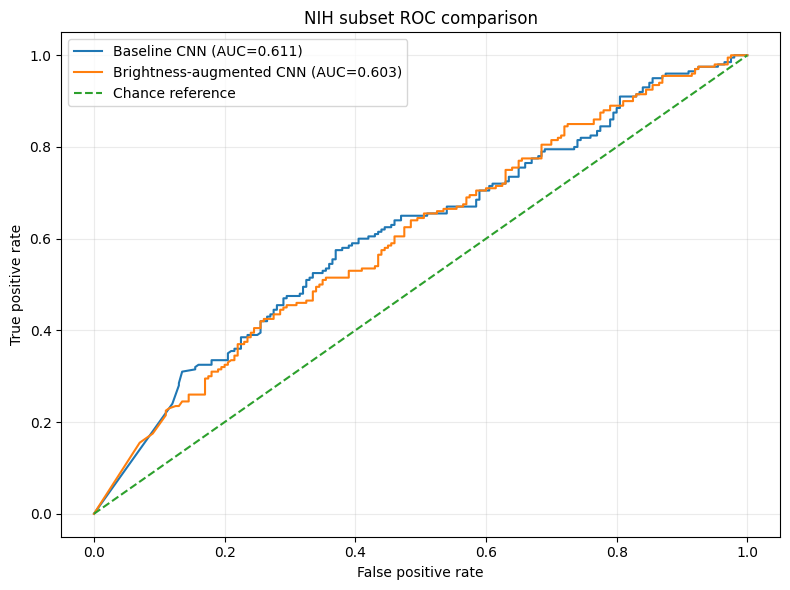

,Model,ROC-AUC,Bootstrap 95% CI lower,Bootstrap 95% CI upper,Bootstrap repetitions
0,Baseline CNN,0.6108,0.5559,0.6664,1000
1,Brightness-augmented CNN,0.6027,0.5451,0.6576,1000


In [95]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.utils import resample

# Use the predictions already generated in previous cells
prediction_sets = {
    "Baseline CNN": nih_baseline_prob,
    "Brightness-augmented CNN": nih_robust_prob
}

rng = np.random.default_rng(42)
bootstrap_results = []

plt.figure(figsize=(8, 6))

for name, scores in prediction_sets.items():
    fpr, tpr, _ = roc_curve(y_nih, scores)
    auc_value = roc_auc_score(y_nih, scores)

    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_value:.3f})")

    boot_aucs = []
    for _ in range(1000):
        indices = rng.integers(0, len(y_nih), len(y_nih))
        y_sample = y_nih[indices]
        p_sample = scores[indices]

        if len(np.unique(y_sample)) == 2:
            boot_aucs.append(roc_auc_score(y_sample, p_sample))

    lower, upper = np.percentile(boot_aucs, [2.5, 97.5])

    bootstrap_results.append({
        "Model": name,
        "ROC-AUC": auc_value,
        "Bootstrap 95% CI lower": lower,
        "Bootstrap 95% CI upper": upper,
        "Bootstrap repetitions": len(boot_aucs)
    })

plt.plot([0, 1], [0, 1], linestyle="--", label="Chance reference")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("NIH subset ROC comparison")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

bootstrap_df = pd.DataFrame(bootstrap_results)
display(bootstrap_df.round(4))

In [96]:
import numpy as np
import pandas as pd

print("Positive image IDs:", len(positive_ids))
print("Negative image IDs:", len(negative_ids))

print("Unique positive image IDs:", len(set(positive_ids)))
print("Unique negative image IDs:", len(set(negative_ids)))

print("Unique positive patients:", len(positive_patients))
print("Unique negative patients:", len(negative_patients))

print(
    "Patient overlap:",
    len(set(positive_patients).intersection(negative_patients))
)

print(
    "Image ID overlap:",
    len(set(positive_ids).intersection(negative_ids))
)

selection_audit = pd.DataFrame([
    {
        "Group": "Pneumonia label",
        "Images": len(positive_ids),
        "Unique image IDs": len(set(positive_ids)),
        "Unique patients": len(positive_patients)
    },
    {
        "Group": "Empty/no positive disease label",
        "Images": len(negative_ids),
        "Unique image IDs": len(set(negative_ids)),
        "Unique patients": len(negative_patients)
    }
])

display(selection_audit)

Positive image IDs: 200
Negative image IDs: 200
Unique positive image IDs: 200
Unique negative image IDs: 200
Unique positive patients: 200
Unique negative patients: 200
Patient overlap: 0
Image ID overlap: 0


,Group,Images,Unique image IDs,Unique patients
0,Pneumonia label,200,200,200
1,Empty/no positive disease label,200,200,200


In [97]:
import os

output_dir = "/content/pneumonia_project"
backup_dir = "/content/drive/MyDrive/Pneumonia_Project_Backup"

os.makedirs(output_dir, exist_ok=True)
os.makedirs(backup_dir, exist_ok=True)

bootstrap_df.to_csv(
    os.path.join(output_dir, "nih_auc_bootstrap_ci.csv"),
    index=False
)

selection_audit.to_csv(
    os.path.join(output_dir, "nih_selection_audit.csv"),
    index=False
)

# Save image identifiers so this selection can be documented
pd.DataFrame({
    "image_id": list(positive_ids) + list(negative_ids),
    "subset_label": [1] * len(positive_ids) + [0] * len(negative_ids),
    "label_interpretation": (
        ["Pneumonia label"] * len(positive_ids)
        + ["Empty label list"] * len(negative_ids)
    )
}).to_csv(
    os.path.join(output_dir, "nih_selected_image_ids.csv"),
    index=False
)

for filename in [
    "nih_auc_bootstrap_ci.csv",
    "nih_selection_audit.csv",
    "nih_selected_image_ids.csv"
]:
    source = os.path.join(output_dir, filename)
    destination = os.path.join(backup_dir, filename)
    pd.read_csv(source).to_csv(destination, index=False)

print("Reports saved locally and to Google Drive.")

Reports saved locally and to Google Drive.


In [98]:
import numpy as np
import pandas as pd

y = np.asarray(y_nih).astype(int)
p_base = np.asarray(nih_baseline_prob).reshape(-1)
p_bright = np.asarray(nih_robust_prob).reshape(-1)

for label, name in [(0, "Empty/no positive disease label"),
                    (1, "Pneumonia label")]:
    idx = np.where(y == label)[0]

    print(f"\n{name} — {len(idx)} images")
    print("Baseline mean score:", round(float(p_base[idx].mean()), 4))
    print("Baseline median score:", round(float(np.median(p_base[idx])), 4))
    print("Baseline predicts pneumonia:",
          int((p_base[idx] >= 0.5).sum()))
    print("Brightness model mean score:",
          round(float(p_bright[idx].mean()), 4))
    print("Brightness model predicts pneumonia:",
          int((p_bright[idx] >= 0.5).sum()))


Empty/no positive disease label — 200 images
Baseline mean score: 0.8285
Baseline median score: 0.9977
Baseline predicts pneumonia: 166
Brightness model mean score: 0.8029
Brightness model predicts pneumonia: 162

Pneumonia label — 200 images
Baseline mean score: 0.9
Baseline median score: 0.9999
Baseline predicts pneumonia: 183
Brightness model mean score: 0.8835
Brightness model predicts pneumonia: 180


Image array shape: (400, 150, 150, 1)
Data type: float32
Pixel minimum: 0.0
Pixel maximum: 1.0
Overall pixel mean: 0.5489257574081421
Overall pixel standard deviation: 0.24836866557598114


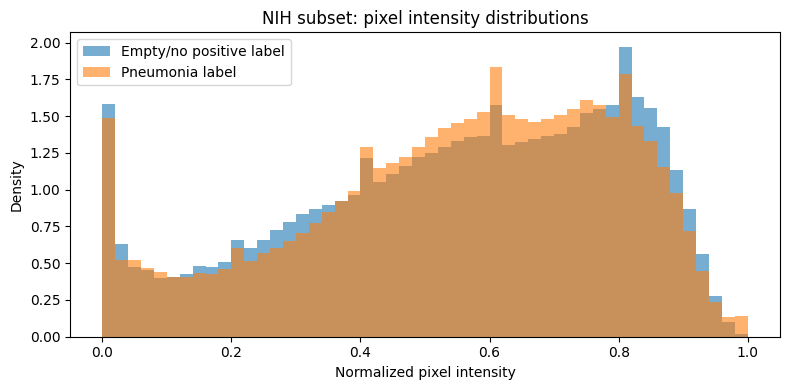

In [99]:
import matplotlib.pyplot as plt

x = np.asarray(x_nih)

print("Image array shape:", x.shape)
print("Data type:", x.dtype)
print("Pixel minimum:", float(x.min()))
print("Pixel maximum:", float(x.max()))
print("Overall pixel mean:", float(x.mean()))
print("Overall pixel standard deviation:", float(x.std()))

plt.figure(figsize=(8, 4))

plt.hist(
    x[y == 0].ravel(),
    bins=50,
    alpha=0.6,
    density=True,
    label="Empty/no positive label"
)

plt.hist(
    x[y == 1].ravel(),
    bins=50,
    alpha=0.6,
    density=True,
    label="Pneumonia label"
)

plt.xlabel("Normalized pixel intensity")
plt.ylabel("Density")
plt.title("NIH subset: pixel intensity distributions")
plt.legend()
plt.tight_layout()
plt.show()

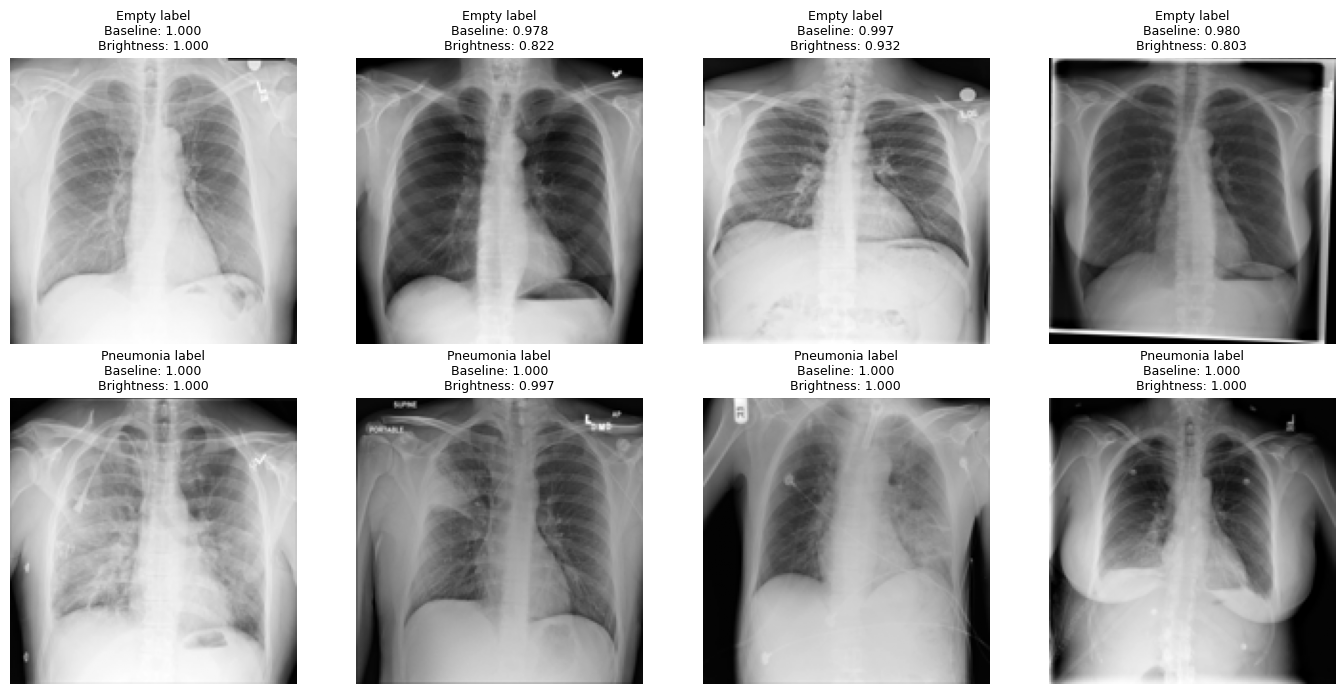

In [100]:
import matplotlib.pyplot as plt
import numpy as np

rng = np.random.default_rng(42)
selected = []

for label in [0, 1]:
    candidates = np.where(y == label)[0]
    selected.extend(
        rng.choice(candidates, size=min(4, len(candidates)),
                   replace=False).tolist()
    )

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.ravel()

for ax, idx in zip(axes, selected):
    ax.imshow(x[idx].squeeze(), cmap="gray")
    actual = "Pneumonia label" if y[idx] == 1 else "Empty label"

    ax.set_title(
        f"{actual}\n"
        f"Baseline: {p_base[idx]:.3f}\n"
        f"Brightness: {p_bright[idx]:.3f}",
        fontsize=9
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [101]:
import numpy as np

print("Baseline model input:", baseline_model.input_shape)
print("Brightness model input:", robust_model.input_shape)
print("NIH images:", x_nih.shape)
print("NIH pixel range:", float(x_nih.min()), float(x_nih.max()))

print("\nOriginal test batch:")
test_images, test_labels = next(test_gen)

print("Image shape:", test_images.shape)
print("Pixel range:", float(test_images.min()), float(test_images.max()))
print("Class mapping:", test_gen.class_indices)

assert x_nih.shape[1:] == (150, 150, 1)
assert np.isfinite(x_nih).all()

print("\nBasic shape and finite-value checks passed.")

Baseline model input: (None, 150, 150, 1)
Brightness model input: (None, 150, 150, 1)
NIH images: (400, 150, 150, 1)
NIH pixel range: 0.0 1.0

Original test batch:
Image shape: (32, 150, 150, 1)
Pixel range: 0.0 1.0
Class mapping: {'NORMAL': 0, 'PNEUMONIA': 1}

Basic shape and finite-value checks passed.


In [102]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, accuracy_score

def evaluate_image_variant(name, images, labels, model):
    probs = model.predict(images, batch_size=32, verbose=0).reshape(-1)
    preds = (probs >= 0.5).astype(int)

    return {
        "Condition": name,
        "ROC-AUC": roc_auc_score(labels, probs),
        "Accuracy": accuracy_score(labels, preds),
        "Mean score": float(probs.mean()),
        "Predicted pneumonia (%)": float(preds.mean() * 100)
    }

x = np.asarray(x_nih, dtype=np.float32)
y = np.asarray(y_nih).astype(int)

variants = {
    "Original": x,
    "Brightness +10%": np.clip(x * 1.10, 0, 1),
    "Brightness -10%": np.clip(x * 0.90, 0, 1),
    "Contrast reduced": np.clip((x - 0.5) * 0.80 + 0.5, 0, 1),
    "Contrast increased": np.clip((x - 0.5) * 1.20 + 0.5, 0, 1)
}

rows = []

for condition, images in variants.items():
    rows.append(evaluate_image_variant(
        condition, images, y, baseline_model
    ))

robustness_table = pd.DataFrame(rows)
display(robustness_table.round(4))

robustness_table.to_csv(
    "/content/pneumonia_project/nih_controlled_shift_experiment.csv",
    index=False
)

robustness_table.to_csv(
    "/content/drive/MyDrive/Pneumonia_Project_Backup/"
    "nih_controlled_shift_experiment.csv",
    index=False
)

print("Saved controlled-shift experiment.")

,Condition,ROC-AUC,Accuracy,Mean score,Predicted pneumonia (%)
0,Original,0.6108,0.5425,0.8642,87.25
1,Brightness +10%,0.6135,0.5400,0.7806,78.00
2,Brightness -10%,0.6057,0.5125,0.9630,96.75
3,Contrast reduced,0.5904,0.5100,0.9849,99.00
4,Contrast increased,0.6119,0.5525,0.7101,72.25


Saved controlled-shift experiment.


In [103]:
original_scores = baseline_model.predict(
    variants["Original"], batch_size=32, verbose=0
).reshape(-1)

stability_rows = []

for condition, images in variants.items():
    scores = baseline_model.predict(
        images, batch_size=32, verbose=0
    ).reshape(-1)

    original_labels = original_scores >= 0.5
    changed_labels = scores >= 0.5

    stability_rows.append({
        "Condition": condition,
        "Mean absolute score change": np.mean(
            np.abs(scores - original_scores)
        ),
        "Classification agreement (%)": 100 * np.mean(
            changed_labels == original_labels
        ),
        "Original positive predictions": int(original_labels.sum()),
        "Changed positive predictions": int(changed_labels.sum())
    })

stability_table = pd.DataFrame(stability_rows)
display(stability_table.round(4))

stability_table.to_csv(
    "/content/pneumonia_project/nih_prediction_stability.csv",
    index=False
)

stability_table.to_csv(
    "/content/drive/MyDrive/Pneumonia_Project_Backup/"
    "nih_prediction_stability.csv",
    index=False
)

print("Saved prediction stability results.")

,Condition,Mean absolute score change,Classification agreement (%),Original positive predictions,Changed positive predictions
0,Original,0.0000,100.00,349,349
1,Brightness +10%,0.0837,90.75,349,312
2,Brightness -10%,0.0988,90.50,349,387
3,Contrast reduced,0.1207,88.25,349,396
4,Contrast increased,0.1541,85.00,349,289


Saved prediction stability results.


In [104]:

import numpy as np
import pandas as pd

def image_statistics(images, name):
    images = np.asarray(images, dtype=np.float32)

    return {
        "Dataset": name,
        "Image count": len(images),
        "Shape": str(images.shape[1:]),
        "Minimum": float(images.min()),
        "Maximum": float(images.max()),
        "Mean pixel intensity": float(images.mean()),
        "Pixel standard deviation": float(images.std()),
        "Image mean - median": float(
            np.median(images.mean(axis=(1, 2, 3)))
        ),
        "Mean image standard deviation": float(
            images.std(axis=(1, 2, 3)).mean()
        )
    }

# Use the original test generator's complete dataset.
# Reset first so the earlier next(test_gen) call does not
# accidentally leave the generator partway through an epoch.
test_gen.reset()

test_images_all = []
test_labels_all = []

for i in range(len(test_gen)):
    images, labels = next(test_gen)
    test_images_all.append(images)
    test_labels_all.append(labels)

x_test_audit = np.concatenate(test_images_all, axis=0)
y_test_audit = np.concatenate(test_labels_all, axis=0).astype(int)

# The NIH arrays should already exist in your notebook.
audit = pd.DataFrame([
    image_statistics(x_test_audit, "Kaggle test"),
    image_statistics(x_nih, "NIH selected subset")
])

print("DATASET STATISTICS")
display(audit.round(4))

print("\nCLASS DISTRIBUTION")
print("Kaggle test:", np.bincount(y_test_audit, minlength=2))
print("NIH subset:", np.bincount(y_nih.astype(int), minlength=2))

print("\nIMAGE SHAPE CHECK")
print("Kaggle:", x_test_audit.shape)
print("NIH:", x_nih.shape)

print("\nNON-FINITE PIXELS")
print("Kaggle:", np.isfinite(x_test_audit).sum()
      != x_test_audit.size)
print("NIH:", np.isfinite(x_nih).sum() != x_nih.size)


DATASET STATISTICS


,Dataset,Image count,Shape,Minimum,Maximum,Mean pixel intensity,Pixel standard deviation,Image mean - median,Mean image standard deviation
0,Kaggle test,624,"(150, 150, 1)",0.0,1.0,0.4747,0.2374,0.4749,0.2256
1,NIH selected subset,400,"(150, 150, 1)",0.0,1.0,0.5489,0.2484,0.5509,0.2259



CLASS DISTRIBUTION
Kaggle test: [234 390]
NIH subset: [200 200]

IMAGE SHAPE CHECK
Kaggle: (624, 150, 150, 1)
NIH: (400, 150, 150, 1)

NON-FINITE PIXELS
Kaggle: False
NIH: False


In [105]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Use the complete Kaggle test set reconstructed in the previous cell.
X = x_test_audit.astype(np.float32)
y = y_test_audit.astype(int)

# Clip transformed pixel values to the valid [0, 1] range.
def shift_brightness(images, factor):
    return np.clip(images * factor, 0.0, 1.0)

def shift_contrast(images, factor):
    # Change contrast around each image's own mean.
    means = images.mean(axis=(1, 2, 3), keepdims=True)
    return np.clip(means + factor * (images - means), 0.0, 1.0)

conditions = {
    "Original": X,
    "Brightness +10%": shift_brightness(X, 1.10),
    "Brightness -10%": shift_brightness(X, 0.90),
    "Contrast reduced": shift_contrast(X, 0.80),
    "Contrast increased": shift_contrast(X, 1.20)
}

models = {
    "Baseline": baseline_model,
    "Brightness-augmented": robust_model
}

results = []

for model_name, model in models.items():
    original_scores = model.predict(X, verbose=0).ravel()
    original_predictions = (original_scores >= 0.5).astype(int)

    for condition, images in conditions.items():
        scores = model.predict(images, verbose=0).ravel()
        predictions = (scores >= 0.5).astype(int)

        results.append({
            "Model": model_name,
            "Condition": condition,
            "ROC-AUC": roc_auc_score(y, scores),
            "Accuracy": accuracy_score(y, predictions),
            "Precision": precision_score(
                y, predictions, zero_division=0
            ),
            "Sensitivity": recall_score(
                y, predictions, zero_division=0
            ),
            "Specificity": (
                ((predictions == 0) & (y == 0)).sum()
                / (y == 0).sum()
            ),
            "F1": f1_score(y, predictions, zero_division=0),
            "Mean absolute score change": np.mean(
                np.abs(scores - original_scores)
            ),
            "Classification agreement (%)": 100 * np.mean(
                predictions == original_predictions
            )
        })

results_df = pd.DataFrame(results)

display(results_df.round(4))

output_path = (
    "/content/pneumonia_project/"
    "kaggle_controlled_robustness_comparison.csv"
)
results_df.to_csv(output_path, index=False)

print("Saved:", output_path)


,Model,Condition,ROC-AUC,Accuracy,Precision,Sensitivity,Specificity,F1,Mean absolute score change,Classification agreement (%)
0,Baseline,Original,0.9391,0.8766,0.8922,0.9128,0.8162,0.9024,0.0000,100.0000
1,Baseline,Brightness +10%,0.9332,0.8782,0.9153,0.8872,0.8632,0.9010,0.0314,96.6346
2,Baseline,Brightness -10%,0.9420,0.8734,0.8608,0.9513,0.7436,0.9038,0.0509,94.8718
3,Baseline,Contrast reduced,0.9372,0.8462,0.8196,0.9667,0.6453,0.8871,0.0972,90.2244
4,Baseline,Contrast increased,0.9372,0.8766,0.9288,0.8692,0.8889,0.8980,0.0597,94.5513
5,Brightness-augmented,Original,0.9543,0.8510,0.8235,0.9692,0.6538,0.8905,0.0000,100.0000
6,Brightness-augmented,Brightness +10%,0.9510,0.8494,0.8246,0.9641,0.6581,0.8889,0.0156,98.5577
7,Brightness-augmented,Brightness -10%,0.9555,0.8397,0.8059,0.9795,0.6068,0.8843,0.0259,96.9551
8,Brightness-augmented,Contrast reduced,0.9490,0.7917,0.7549,0.9872,0.4658,0.8556,0.0831,91.8269
9,Brightness-augmented,Contrast increased,0.9542,0.8798,0.8689,0.9513,0.7607,0.9082,0.0510,94.8718


Saved: /content/pneumonia_project/kaggle_controlled_robustness_comparison.csv


In [106]:

import pandas as pd

df = results_df.copy()

metric_cols = [
    "ROC-AUC",
    "Accuracy",
    "Sensitivity",
    "Specificity",
    "F1"
]

original = (
    df[df["Condition"] == "Original"]
    .set_index("Model")
)

summary = []

for _, row in df.iterrows():
    base = original.loc[row["Model"]]

    record = {
        "Model": row["Model"],
        "Condition": row["Condition"]
    }

    for metric in metric_cols:
        record[f"{metric} change"] = (
            row[metric] - base[metric]
        )

    summary.append(record)

change_df = pd.DataFrame(summary)

display(change_df.round(4))

path = (
    "/content/pneumonia_project/"
    "controlled_shift_metric_changes.csv"
)
change_df.to_csv(path, index=False)
print("Saved:", path)


,Model,Condition,ROC-AUC change,Accuracy change,Sensitivity change,Specificity change,F1 change
0,Baseline,Original,0.0000,0.0000,0.0000,0.0000,0.0000
1,Baseline,Brightness +10%,-0.0060,0.0016,-0.0256,0.0470,-0.0014
2,Baseline,Brightness -10%,0.0029,-0.0032,0.0385,-0.0726,0.0014
3,Baseline,Contrast reduced,-0.0019,-0.0304,0.0538,-0.1709,-0.0153
4,Baseline,Contrast increased,-0.0019,0.0000,-0.0436,0.0726,-0.0044
5,Brightness-augmented,Original,0.0000,0.0000,0.0000,0.0000,0.0000
6,Brightness-augmented,Brightness +10%,-0.0033,-0.0016,-0.0051,0.0043,-0.0016
7,Brightness-augmented,Brightness -10%,0.0012,-0.0112,0.0103,-0.0470,-0.0062
8,Brightness-augmented,Contrast reduced,-0.0053,-0.0593,0.0179,-0.1880,-0.0349
9,Brightness-augmented,Contrast increased,-0.0001,0.0288,-0.0179,0.1068,0.0177


Saved: /content/pneumonia_project/controlled_shift_metric_changes.csv


In [107]:

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

# Reuse the original held-out test images and labels.
X = x_test_audit.astype(np.float32)
y = y_test_audit.astype(int)

# Predict on the unmodified test images.
p_baseline = baseline_model.predict(X, verbose=0).ravel()
p_augmented = robust_model.predict(X, verbose=0).ravel()

print("Baseline AUC:", round(roc_auc_score(y, p_baseline), 4))
print("Augmented AUC:", round(roc_auc_score(y, p_augmented), 4))

# Paired bootstrap: both models use identical resampled indices.
rng = np.random.default_rng(42)
n = len(y)
n_bootstrap = 2000

auc_base_samples = []
auc_aug_samples = []
auc_diff_samples = []

for _ in range(n_bootstrap):
    idx = rng.integers(0, n, size=n)

    # AUC is undefined if a resample contains only one class.
    if np.unique(y[idx]).size < 2:
        continue

    auc_b = roc_auc_score(y[idx], p_baseline[idx])
    auc_a = roc_auc_score(y[idx], p_augmented[idx])

    auc_base_samples.append(auc_b)
    auc_aug_samples.append(auc_a)
    auc_diff_samples.append(auc_a - auc_b)

def ci95(values):
    return np.percentile(values, [2.5, 97.5])

base_ci = ci95(auc_base_samples)
aug_ci = ci95(auc_aug_samples)
diff_ci = ci95(auc_diff_samples)

print("\nPAIRED BOOTSTRAP RESULTS")
print(f"Baseline AUC 95% CI: [{base_ci[0]:.4f}, {base_ci[1]:.4f}]")
print(f"Augmented AUC 95% CI: [{aug_ci[0]:.4f}, {aug_ci[1]:.4f}]")
print(f"AUC difference (augmented - baseline): "
      f"{roc_auc_score(y, p_augmented) - roc_auc_score(y, p_baseline):.4f}")
print(f"Paired AUC difference 95% CI: "
      f"[{diff_ci[0]:.4f}, {diff_ci[1]:.4f}]")

summary = pd.DataFrame([
    {
        "Comparison": "Baseline AUC",
        "Estimate": roc_auc_score(y, p_baseline),
        "CI lower": base_ci[0],
        "CI upper": base_ci[1]
    },
    {
        "Comparison": "Brightness-augmented AUC",
        "Estimate": roc_auc_score(y, p_augmented),
        "CI lower": aug_ci[0],
        "CI upper": aug_ci[1]
    },
    {
        "Comparison": "Paired AUC difference",
        "Estimate": (
            roc_auc_score(y, p_augmented)
            - roc_auc_score(y, p_baseline)
        ),
        "CI lower": diff_ci[0],
        "CI upper": diff_ci[1]
    }
])

display(summary.round(4))

path = "/content/pneumonia_project/paired_auc_bootstrap.csv"
summary.to_csv(path, index=False)
print("Saved:", path)


Baseline AUC: 0.9391
Augmented AUC: 0.9543

PAIRED BOOTSTRAP RESULTS
Baseline AUC 95% CI: [0.9194, 0.9571]
Augmented AUC 95% CI: [0.9388, 0.9688]
AUC difference (augmented - baseline): 0.0152
Paired AUC difference 95% CI: [0.0084, 0.0224]


,Comparison,Estimate,CI lower,CI upper
0,Baseline AUC,0.9391,0.9194,0.9571
1,Brightness-augmented AUC,0.9543,0.9388,0.9688
2,Paired AUC difference,0.0152,0.0084,0.0224


Saved: /content/pneumonia_project/paired_auc_bootstrap.csv
